# Trying things out

In [942]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
import importlib
import cProfile
import itertools
import timeit
import json
import ctmc
import utils
import plot
import networkx as nx
import os

importlib.reload(plot)

<module 'plot' from '/home/tohme/.julia/dev/LLROpt/plot.py'>

## Understanding iterators

In [53]:
a = [np.array([0,1]), np.array([[1,1],[3,6]])]
it = itertools.accumulate(a, ctmc.matmul_r)
b = np.array(list(it))
np.sum(b, axis=1)

array([1., 9.])

In [70]:
setup = """
import numpy as np
import ctmc
import itertools
a = [np.array([0,1])] + [np.array([[1,2],[3,4]])]*100000
it = itertools.accumulate(a, ctmc.matmul_r)
"""

stmt = """
np.log(np.sum(np.array(list(it)), axis=1))
"""

timeit.timeit(stmt, setup, number=1)

0.3747418439888861

In [71]:
stmt2 = """
np.array([np.log(np.sum(i)) for i in it])
"""

timeit.timeit(stmt2, setup, number=1)

0.5998997629940277

## Profiling

### ctmc.ir_full()

In [4]:
import pstats
from pstats import SortKey

nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)
args = (c, dc, on_ind, idist, n, nb, na)

logrates = np.array([1,1,1,1,1,1,1,1])
rates = 10.0 ** logrates

cProfile.run('ctmc.ir_full(rates, *args)', 'irstats')

In [33]:
p = pstats.Stats('irstats')
p.sort_stats(SortKey.CUMULATIVE).print_stats()

Mon Apr 22 16:31:15 2024    irstats

         4999667 function calls in 8.737 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    8.737    8.737 {built-in method builtins.exec}
        1    0.002    0.002    8.737    8.737 <string>:1(<module>)
        1    0.016    0.016    8.735    8.735 /home/tohme/phd/flython/ctmc.py:369(ir_full)
        1    4.267    4.267    4.267    4.267 /home/tohme/phd/flython/ctmc.py:126(generate)
        2    0.107    0.054    2.713    1.357 /home/tohme/phd/flython/ctmc.py:329(ll_full)
   499874    0.901    0.000    2.202    0.000 /home/tohme/phd/flython/ctmc.py:401(matmul_r)
        1    1.671    1.671    1.695    1.695 /home/tohme/phd/flython/utils.py:74(get_residence_times)
   499889    0.315    0.000    1.267    0.000 /home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/numpy/core/fromnumeric.py:2177(sum)
   499898    0.340    0.000    0.919    0.000 /h

In [32]:
p.print_callers(.99)

   Ordered by: internal time
   List reduced from 115 to 114 due to restriction <0.99>

Function                                                                                                              was called by...
                                                                                                                          ncalls  tottime  cumtime
/home/tohme/phd/flython/ctmc.py:126(generate)                                                                         <-       1    4.267    4.267  /home/tohme/phd/flython/ctmc.py:369(ir_full)
/home/tohme/phd/flython/utils.py:74(get_residence_times)                                                              <-       1    1.671    1.695  /home/tohme/phd/flython/ctmc.py:369(ir_full)
/home/tohme/phd/flython/ctmc.py:401(matmul_r)                                                                         <-  499874    0.901    2.202  /home/tohme/phd/flython/ctmc.py:329(ll_full)
{method 'reduce' of 'numpy.ufunc' objects}         

In [ ]:
np.ones((500000, 4, 4))

### ctmc.Generator.generate()

In [19]:
nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)
args = (c, dc, on_ind, idist, n, nb, na)

exp_name = 'outcmaes-diff-limited-log-search-space-general-4s-ir-acc-20240408'
logrates = utils.cmaes_output_to_arr('exps/data/'+exp_name+'/xrecentbest.dat')[-3, 5:13]

rates = 10.0 ** logrates
on = np.where(on_ind)[0]

Q = utils.build_mat(rates, c, nb, na)
C = ctmc.Generator(Q, n, initial_dist=idist)

In [20]:
cProfile.run('C.generate()', sort=0)

         5 function calls in 4.254 seconds

   Ordered by: call count

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    4.254    4.254 {built-in method builtins.exec}
        1    4.254    4.254    4.254    4.254 ctmc.py:126(generate)
        1    0.000    0.000    4.254    4.254 <string>:1(<module>)
        1    0.000    0.000    0.000    0.000 {built-in method numpy.arange}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}




### utils.get_residence_times()

In [75]:
cProfile.run('utils.get_residence_times(C.r[:,0], C.t[:,0], on)', sort=2)

         500004 function calls in 1.724 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    1.724    1.724 {built-in method builtins.exec}
        1    0.002    0.002    1.724    1.724 <string>:1(<module>)
        1    1.698    1.698    1.722    1.722 utils.py:74(get_residence_times)
   500000    0.024    0.000    0.024    0.000 {method 'keys' of 'dict' objects}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}




In [73]:
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)
t_on = np.array(list(res_times['on'].values()))
t_off = np.array(list(res_times['off'].values()))
t_onoff = np.stack((t_on, t_off), axis=1)
t_onoff = np.cumsum(np.concatenate(t_onoff))
t = np.sum(t_on + t_off)

args_ll = (on_ind, t_on, t_off, idist, nb, na)

### ctmc.ll_full()

In [74]:
cProfile.run('ctmc.ll_full(rates, c, *args_ll)', sort=2)

         2223097 function calls in 1.349 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    1.349    1.349 {built-in method builtins.exec}
        1    0.007    0.007    1.349    1.349 <string>:1(<module>)
        1    0.055    0.055    1.342    1.342 ctmc.py:329(ll_full)
   246978    0.443    0.000    1.072    0.000 ctmc.py:372(matmul_r)
   246983    0.149    0.000    0.611    0.000 fromnumeric.py:2177(sum)
   246985    0.160    0.000    0.446    0.000 fromnumeric.py:71(_wrapreduction)
   246991    0.195    0.000    0.195    0.000 {method 'reduce' of 'numpy.ufunc' objects}
        2    0.032    0.016    0.123    0.061 ctmc.py:189(fpt)
        2    0.085    0.043    0.091    0.045 ctmc.py:151(P)
   246985    0.077    0.000    0.077    0.000 fromnumeric.py:72(<dictcomp>)
        1    0.049    0.049    0.057    0.057 utils.py:103(alternate)
        1    0.033    0.033    0.033    0.033 {built-in 

### ctmc.ll_full_fast()

In [61]:
args_ll = (on_ind, t_on, t_off, v_on, nb, na)

cProfile.run('ctmc.ll_full_fast(rates, c, *args_ll)', sort=2)

         292 function calls in 0.404 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.404    0.404 {built-in method builtins.exec}
        1    0.000    0.000    0.404    0.404 <string>:1(<module>)
        1    0.176    0.176    0.403    0.403 ctmc.py:430(ll_full_fast)
        2    0.060    0.030    0.220    0.110 ctmc.py:201(fpt)
        2    0.154    0.077    0.160    0.080 ctmc.py:163(P)
        2    0.004    0.002    0.004    0.002 {method 'flatten' of 'numpy.ndarray' objects}
        5    0.004    0.001    0.004    0.001 {built-in method numpy.zeros}
       13    0.003    0.000    0.003    0.000 {method 'reduce' of 'numpy.ufunc' objects}
        7    0.000    0.000    0.003    0.000 fromnumeric.py:71(_wrapreduction)
        5    0.000    0.000    0.003    0.001 fromnumeric.py:2177(sum)
        2    0.002    0.001    0.002    0.001 numeric.py:932(tensordot)
        2    0.000    0.000  

### ctmc.ir_full_fast()

In [2]:
import pstats
from pstats import SortKey

nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0, 1, 0, 1])
idist = np.array([0.25] * 4)
args = (c, dc, on_ind, idist, n, nb, na)

logrates = np.array([1, 1, 1, 1, 1, 1, 1, 1])
rates = 10.0 ** logrates

cProfile.run('ctmc.ir_full_fast(rates, *args)', 'irstats')
p = pstats.Stats('irstats')
p.sort_stats(SortKey.CUMULATIVE).print_stats()


: 

## Vectorizing get_residence_times

In [76]:
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)

In [22]:
on = np.array([1,3])
on_ = np.outer(on, np.ones(n))

In [23]:
a = np.array([0,1,3,1,2,3,2,4])
b = a / 10
hset = np.array([1,3])
hset_ = np.outer(hset, np.ones(len(a)))

hset_

array([[1., 1., 1., 1., 1., 1., 1., 1.],
       [3., 3., 3., 3., 3., 3., 3., 3.]])

In [25]:
c = np.where(a == hset_, b, 0)
d = np.sum(c, axis=0)
d

array([0. , 0.1, 0.3, 0.1, 0. , 0.3, 0. , 0. ])

In [26]:
c

array([[0. , 0.1, 0. , 0.1, 0. , 0. , 0. , 0. ],
       [0. , 0. , 0.3, 0. , 0. , 0.3, 0. , 0. ]])

In [129]:
d * np.roll(d, 1) > 0

array([False, False,  True,  True, False, False, False, False])

# Interfacing with C

## ctmc.matmul_r() C interface

In [2]:
from ctypes import *
import sys
import os

lib_path = os.path.join(sys.path[0], 'cpython/matmul_%s.so' % (sys.platform))
try:
    matmul_lib = cdll.LoadLibrary(lib_path)
except:
    print('OS %s not recognized' % (sys.platform))

ctypes_matmul_r = matmul_lib.matmul_r
ctypes_accumulate = matmul_lib.accumulate
ctypes_matmul_r.restype = None
ctypes_accumulate.restype = None

In [47]:
# Python

seed = 42
rng = np.random.default_rng(seed)

# rate bounds
log_lb = -5
difflimit = 0.124
log_ub = 5
log_dl = np.log10(difflimit)

#                       k_0^0   k_0^1   k_1^0   k_1^1   k_2^0   k_2^1   k_3^0   k_3^1
log_lbounds = np.array([log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb])
log_ubounds = np.array([log_dl, log_ub, log_dl, log_ub, log_ub, log_ub, log_ub, log_ub])

# set up parameters
nb, na = 1, 1
nstates = 2 ** (nb + na)
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)
on = np.where(on_ind)[0]
off = np.arange(nstates)[~on]

# sample rates
logrates = rng.uniform(log_lbounds, log_ubounds)
rates = 10.0 ** logrates

# build rate matrix and simulate
Q = utils.build_mat(rates, c, nb, na)
C = ctmc.Generator(Q, n, initial_dist=idist)
C.generate()

# residence times in on and off partitions
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)
t_on = np.array(list(res_times['on'].values()))
t_off = np.array(list(res_times['off'].values()))

# only keep nonzero residence times
start_in_on = t_on[0] > 0
t_on = t_on[(t_on > 0)]
t_off = t_off[(t_off > 0)]

# make res time arrays of equal length
minlen = min(len(t_on), len(t_off))
t_on = t_on[:minlen]
t_off = t_off[:minlen]
njumps = minlen

# first-passage time probability densities
R = ctmc.fpt(Q, off, t_on)
S = ctmc.fpt(Q, on, t_off)

R_ = R[..., on, :][..., off]
S_ = S[..., off, :][..., on]

# concatenate into an alternating on-off sequence of matrices
if start_in_on:
    D = utils.alternate(R_, S_)
else:
    D = utils.alternate(S_, R_)

# prepend the initial distribution conditioned on start state
p_on = idist @ on_ind
p_off = idist @ (np.ones(nstates) - on_ind)
D.appendleft(idist[on] / p_on if start_in_on else idist[off] / p_off)

# reduce the sequence to a single vector, rescaling along the way
it = np.array(list(itertools.accumulate(D, ctmc.matmul_r)))

llr_vec_python = np.array(it)
llr_traj_python = np.log(np.sum(it, axis=1))

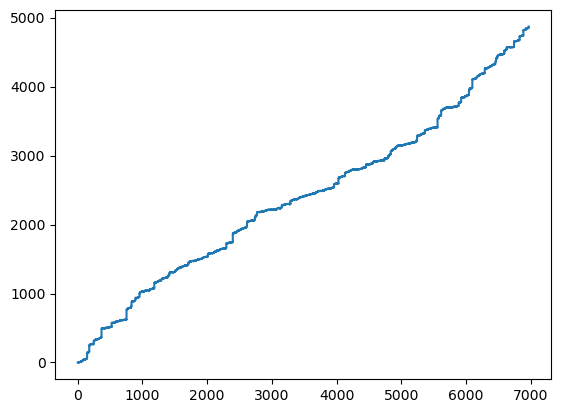

In [4]:
time = np.stack((t_on, t_off), axis=1)
time = np.concatenate(time)
w = 4000
plt.plot(np.cumsum(time)[:w], np.cumsum(llr_traj_python)[:w])

### Toy example

In [25]:
n = 2
m = 2
N_R = 2
N_S = 2
N = N_R + N_S


v = np.array([0,1])
Rlist = np.array([1,0,0,1,0,1,1,0])
Slist = np.array([1,1,2,2,1,1,2,2])

c_m = c_int(m)
c_n = c_int(n)
c_N = c_int(N)
c_v = (c_double * m)(*v)
c_Rlist = (c_double * (m*n*N_R))(*Rlist)
c_Slist = (c_double * (m*n*N_S))(*Slist)
c_vlist = (c_double * (m*N))()

c_M = (c_double * (m*n))(*np.array([0,1,2,3]))
c_w = (c_double * (m))()

In [17]:
ctypes_matmul_r(c_m, c_n, c_v, c_M, c_w)
np.array(c_w)

array([2., 3.])

In [18]:
# C

ctypes_accumulate(c_m, c_n, c_N, c_v, c_Rlist, c_Slist, c_vlist)

In [19]:
c_vlist[:]

[0.0, 1.0, 2.0, 2.0, 0.5, 0.5, 1.5, 1.5]

### Real trajectory

In [57]:
m = len(on)
n = len(off)
N_R = R_.shape[0]
N_S = S_.shape[0]
N = N_R + N_S
v_on = idist[on] / p_on
v_off = idist[off] / p_off

Rlist = R_.flatten()
Slist = S_.flatten()

c_m = c_int(m)
c_n = c_int(n)
c_N = c_int(N)
c_von = (c_double * m)(*v_on)
c_voff = (c_double * n)(*v_off)
c_Rlist = (c_double * (m*n*N_R))(*Rlist)
c_Slist = (c_double * (m*n*N_S))(*Slist)
c_vlist = (c_double * (m*N))()

In [17]:
if start_in_on:
    ctypes_accumulate(c_m, c_n, c_N, c_von, c_Rlist, c_Slist, c_vlist)
else:
    ctypes_accumulate(c_n, c_m, c_N, c_voff, c_Slist, c_Rlist, c_vlist)

In [18]:
a, b = llr_vec_python[1:].flatten(), c_vlist[:]

np.allclose(a, b)

True

### Comparing both implementations in the ctmc file

In [58]:
import time

start = time.time()
ll_traj_python = ctmc.ll_full(rates, c, on_ind, t_on, t_off, v_on, nb, na)
mid = time.time()
ll_traj_c = ctmc.ll_full_fast(rates, c, on_ind, t_on, t_off, v_on, nb, na)
end = time.time()

In [59]:
np.allclose(ll_traj_python[1:], ll_traj_c)

True

In [60]:
print("python: ", mid-start)
print("C: ", end - mid)

python:  1.869136095046997
C:  0.40924930572509766


## ctmc.Generator.generate() C interface

In [2]:
from ctypes import *
import sys
import os

lib_path = os.path.join(sys.path[0], 'cpython/generate_%s.so' % (sys.platform))
try:
    generate_lib = cdll.LoadLibrary(lib_path)
except:
    print('OS %s not recognized' % (sys.platform))

ctypes_generate = generate_lib.generate
ctypes_generate.restype = None

# from ctypes import *
# import sys
# import os

# lib_path = os.path.join(sys.path[0], 'cpython/gillespie_C_%s.so' % (sys.platform))
# try:
#     gillespie_lib = cdll.LoadLibrary(lib_path)
# except:
#     print('OS %s not recognized' % (sys.platform))

# python_gillespie = gillespie_lib.gillespie
# python_gillespie.restype = None

In [4]:
nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)

seed = 45
rng = np.random.default_rng(seed)

# rate bounds
log_lb = -1
difflimit = 0.124
log_ub = 1
log_dl = np.log10(difflimit)

#                       k_0^0   k_0^1   k_1^0   k_1^1   k_2^0   k_2^1   k_3^0   k_3^1
log_lbounds = np.array([log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb])
log_ubounds = np.array([log_dl, log_ub, log_dl, log_ub, log_ub, log_ub, log_ub, log_ub])

# sample rates
logrates = rng.uniform(log_lbounds, log_ubounds)
rates = 10.0 ** logrates
Q = utils.build_mat(rates, c, nb, na)

states, hold_times, t_on, t_off = ctmc.generate(rates, c, n, idist, on_ind, nb, na)

: 

In [3]:
nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0, 1, 0, 1])
idist = np.array([0.25] * 4)
args = (c, dc, on_ind, idist, n, nb, na)

logrates = np.array([1, 1, 1, 1, 1, 1, 1, 1])
rates = 10.0 ** logrates

ns=2 ** (nb + na)
Q=utils.build_mat(rates, c, nb, na).T
K=-np.diag(Q)
k=Q+np.diag(K)
C=np.cumsum(k,0)/K
flattenC=np.transpose(C).flatten()
s0=np.random.default_rng().choice(np.arange(ns), p=idist)

# initialize the ctypes variables
c_K = (c_double * ns)(*K)
c_C = (c_double * (ns**2))(*flattenC)
c_deltat = (c_double * n)()
c_ton = (c_double * n)()
c_toff = (c_double * n)()
c_s = (c_int *n)()
c_on_ind = (c_int *ns)(*on_ind)

# simulate
ctypes_generate(
    c_int(ns), 
    c_int(s0), 
    c_int(n), 
    c_K,
    c_C, 
    c_on_ind,
    c_s, 
    c_deltat,
    c_ton,
    c_toff
)

In [4]:
import scipy

# some tests
assert len(t_on) == len(t_off)

Q = utils.build_mat(rates, c, nb, na)
Q = Q.T
Q_nodiag = Q - np.diag(np.diag(Q))
diagQ = np.diag(Q)
K=-np.diag(Q)
k=Q+np.diag(K)
values, counts = np.unique(states, return_counts=True)

u, s, vh = scipy.linalg.svd((k-np.diag(K))/K)
print(vh[-1,:]/sum(vh[-1,:]))
print(ctmc.P_ss(Q.T))
print(counts / n)

NameError: name 't_on' is not defined

In [51]:
values

array([-1,  0,  1,  2,  3], dtype=int32)

In [36]:
counts

array([     7,      7, 249993, 249993])

# Fully-connected network

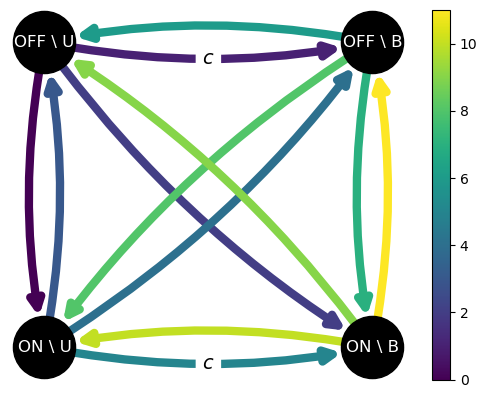

array([[-12.,   0.,  10.,   2.],
       [  3., -57.,   4.,  50.],
       [  6.,   8., -21.,   7.],
       [  9.,  10.,  11., -30.]])

In [4]:
import networkx as nx
importlib.reload(plot)

G = nx.DiGraph()
G.add_nodes_from(range(4))
edges = np.array([(0,1),(0,2),(0,3),
                  (1,0),(1,2),(1,3),
                  (2,0),(2,3),(2,1),
                  (3,0),(3,1),(3,2)])
input_edges = [(0,2), (1,3)]
weights = np.arange(12)[:, None]
base_rates = np.concatenate((edges, weights), axis=1)

plot.draw_circuit(base_rates, input_edges)
utils.build_mat(base_rates, input_edges, 10)

# Tinkering

In [2]:
import numpy as np
import copy

def fpt(Q, hset, t):
    """
    Matrix of PDFs of the first-passage time to hit any state in hset
    """
    nstates = len(Q)
    Q_h = copy.deepcopy(Q)
    Q_h[hset] = np.zeros(nstates)  # rows of hitting set are zeroed

    print(Q_h, '\n')

    print(ctmc.P(Q_h, t))

    return Q_h @ ctmc.P(Q_h, t)

Q = np.array([-1.0, 0.6, 0.4, 
              0.0, -1.5, 1.5, 
              1.0, 1.0, -2.0])

Q = Q.reshape((3, 3))
hset = np.array([0])

t = 1

fpt(Q, hset, t)

[[ 0.   0.   0. ]
 [ 0.  -1.5  1.5]
 [ 1.   1.  -2. ]] 

[[1.         0.         0.        ]
 [0.28212062 0.38383322 0.33404615]
 [0.50481806 0.22269744 0.2724845 ]]


array([[ 0.        ,  0.        ,  0.        ],
       [ 0.33404615, -0.24170368, -0.09234247],
       [ 0.2724845 , -0.06156165, -0.21092286]])

# Getting rid of alternate()

In [61]:
edges = np.array([(0,1), (1,0), (1,2), (2,1)])
input_edges = [(1,0), (1,2)]
on_ind = np.array([1,0,1])
c = 1
dc = 0.1
n = 5
idist = np.ones(3) / 3

logrates = np.random.default_rng().uniform(low=0, high=1, size=4)
rates = 10.0 ** logrates
rates = rates[:, np.newaxis]
weighted_edges = np.concatenate((edges, rates), axis=1)

nstates = len(on_ind)
off_ind = np.ones(nstates) - on_ind
on = np.where(on_ind)[0]
off = np.where(off_ind)[0]

# building the rate matrix and simulating 
Q = utils.build_mat(weighted_edges, input_edges, c)
C = ctmc.Generator(Q, n, initial_dist=idist)
C.generate()

# residence times in on and off partitions
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)
t_on = np.array(list(res_times['on'].values()))
t_off = np.array(list(res_times['off'].values()))

# only keep nonzero residence times
start_in_on = t_on[0] > 0
t_on = t_on[(t_on > 0)]
t_off = t_off[(t_off > 0)]

# make res time arrays of equal length
minlen = min(len(t_on), len(t_off))
t_on = t_on[:minlen]
t_off = t_off[:minlen]

# total duration of trajectory
t = np.sum(t_on + t_off)

# conditional initial distributions
idist_on = idist[on] / (idist @ on_ind)
idist_off = idist[off] / (idist @ off_ind)

if start_in_on:
    args_ll = (on_ind, t_on, t_off, idist_on)
    ind_set = on_ind
    t_set, t_comp = t_on, t_off
    idist_set = idist_on
else:
    args_ll = (off_ind, t_off, t_on, idist_off)
    ind_set = off_ind
    t_set, t_comp = t_off, t_on
    idist_set = idist_off

assert len(t_set) == len(t_comp)

ind_comp = np.ones_like(ind_set) - ind_set
_set = np.where(ind_set)[0]
_comp = np.where(ind_comp)[0]

# matrices of first-passage time PDFs
R = ctmc.fpt(Q, _comp, t_set)
S = ctmc.fpt(Q, _set, t_comp)

# zero-out slices of R except from on->off and from S except from off->on
R[..., _comp, :] = 0
R[..., _set] = 0
S[..., _set, :] = 0
S[..., _comp] = 0

# concatenate into an alternating on-off sequence of matrices
D = utils.alternate(R_, S_)

# prepend the initial distribution conditioned on start state
D.appendleft(idist_set)

# reduce the sequence to a single vector, rescaling along the way
it = np.array(list(itertools.accumulate(D, ctmc.matmul_r)))

ll = np.log(np.sum(it, axis=1))



(2,) (2, 1)
(1,) (1, 2)
(2,) (2, 1)
(1,) (1, 2)


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.

In [52]:
on_bool = np.array([1,0,1], dtype='bool')
off_bool = np.logical_not(on_bool)

In [76]:
import copy

S1 = copy.deepcopy(S)
R1 = copy.deepcopy(R)


In [77]:
R1[..., _comp, :] = 0
R1[..., _set] = 0
S1[..., _set, :] = 0
S1[..., _comp] = 0

In [81]:
R1

array([[[0.        , 0.64876013, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 1.07623634, 0.        ]],

       [[0.        , 0.46003018, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.90248879, 0.        ]]])

In [82]:
S1

array([[[0.        , 0.        , 0.        ],
        [2.05080202, 0.        , 4.99507377],
        [0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        ],
        [1.36374185, 0.        , 3.32162301],
        [0.        , 0.        , 0.        ]]])

In [104]:
idist = np.ones(3) / 3
idist[_comp] = 0
idist = idist / np.sum(idist)
# np.outer(idist, np.ones(3))
A = np.zeros_like(Q)
A[_set] = idist
A

array([[0.5, 0. , 0.5],
       [0. , 0. , 0. ],
       [0.5, 0. , 0.5]])

In [115]:


D = np.stack((R1, S1), axis=1)
D = np.concatenate(D)
list(itertools.accumulate(D, ctmc.matmul_r))

[array([[0.        , 0.64876013, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 1.07623634, 0.        ]]),
 array([[0.77129351, 0.        , 1.87861527],
        [0.        , 0.        , 0.        ],
        [1.27950851, 0.        , 3.1164585 ]]),
 array([[0.        , 0.29098547, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.48271946, 0.        ]]),
 array([[0.51289458, 0.        , 1.24924115],
        [0.        , 0.        , 0.        ],
        [0.85084727, 0.        , 2.07238186]])]

# Gradient descent
 Intuition: if the cost function g(x) initially grows faster than f(x) along the optimal boundary, then grows slower after some point, then the boundary will be non-concave

In [2]:
import numdifftools as nd

a = 3e-3        # um
D_tf = 7.4      # um^2/s
D_cplx = 0.1    # um^2/s
c = 5.6         # um^-3
dc = 0.1 * c
dl_tf = 4*a*D_tf
ub = 5*7.4/11
max_ir_full = 0.5 * (dc/c)**2 * (1/(c*4*a*D_tf + 1/ub)) ** (-1)

log_ub = np.log10(ub)
log_dl_tf = np.log10(dl_tf)
log_lb = -5 + np.log10(7.4/11)

log_lbounds = np.ones(8) * log_lb
log_ubounds = np.ones(8) * log_ub

# diff-limited upper bounds
log_ubounds[0] = log_dl_tf
log_ubounds[2] = log_dl_tf

# lower bounds
log_lbounds[0] = min(log_lb, log_dl_tf - 1)
log_lbounds[2] = min(log_lb, log_dl_tf - 1)

lbounds = 10.0 ** log_lbounds
ubounds = 10.0 ** log_ubounds
bounds = [log_lbounds, log_ubounds]

########### Circuit
edges = np.array([(0,2), (0,1), (1,3), (1,0), (2,0), (2,3), (3,1), (3,2)])#, (0,3), (3,0)])
input_edges = [(0,2), (1,3)]#, (0,3)]

########### CMA parameters
maxfevals = 10000
sigma0 = (log_ub) / 4
x0 = (log_ubounds + log_lbounds) / 2
# x0 = np.array([-1.05,-4,-1.05,0.69,-4,0.69,0.69,-4])    # true optimum
weighted_eges = np.concatenate((edges, x0[:, np.newaxis]), axis=1)

on_ind = np.array([0,1,0,1])
betas = np.logspace(-8, -3, 30)

In [45]:
setup = """
import importlib
import numpy as np
import ctmc
importlib.reload(ctmc)
import timeit

Q = np.array([[-2, 2], [2, -2]])
weighted_edges = np.array([(0,1,2), (1,0,2)])
input_edges = np.array([(0,1)])
c = 1.0000000001
on_ind = np.array([0,1])
t_set = np.array([1,2,3])
t_comp = np.array([2,3,4])
ind_set = np.array([0,1])
idist_set = np.array([0.5])
"""

timeit.timeit("ctmc.ll_full(weighted_edges, input_edges, c, ind_set, t_set, t_comp, idist_set)", setup=setup, number=10000)

1.5585023909807205

In [2]:
import importlib
import numpy as np
import ctmc
importlib.reload(ctmc)
import timeit
import matplotlib.pyplot as plt

weighted_edges = np.array([(0,1,0.5), (1,0,2)])
input_edges = [(0,1)]
c = 1
dc = 0.1
on_ind = np.array([0,1])
idist = np.ones(2) / 2
n = 1000

N = 1000
acc = 0
for i in range(N):
    t_on, t_off, llr = ctmc.ir_full(weighted_edges, input_edges, c, dc, on_ind, idist, n)
    acc += llr[-1] / np.sum((t_on, t_off))

acc / N

# fig, ax = plt.subplots(1,1)

# ax.hist(times, density=True)
# ax.plot()

# times = np.zeros(3)

# for i in range(n):
#     si = G.r[i, 0]
#     times[si] += G.t[i, 0]

# times /= np.sum(G.t)
# times

0.0018624739325114993

In [98]:
llr.shape

(5001,)

In [2]:
llr

array([0.        , 0.0651039 , 0.0651039 , ..., 3.67476954, 3.61412779,
       3.61412779])

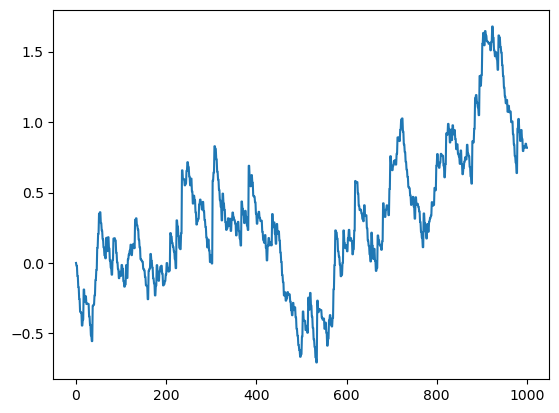

In [7]:
plt.plot(llr)

# Problem with pareto fronts

In [6]:
# try to isolate the problem(s)
# 1. optima should be the same under rescaling of the parameter bounds
# 2. beta should be the slope of the curve

# function to minimize
def f(x):
    return -x[0]**2 - x[1]**2

# constraint
def g(x, c):
    return x[1] - c*x[0]

def L(x, c, beta):
    return f(x) + beta*g(x, c)

# bounds
lb = [0, 0]
ub = [5, 5]
bounds = [lb, ub]

# lagrange multiplier
betas = np.linspace(0, 10, 20)
c = 1

# cma settings
x0 = [1,1]
sigma0 = 0.25
maxfevals = 5000
output = []

for key, beta in enumerate(betas):

    args = (c, beta)

    opts = {'maxfevals': maxfevals,
            'bounds': bounds,
            'verb_append': 0}

    xopt, es = cma.fmin2(L, x0, sigma0, options=opts, args=args)
    output.append(es)

(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=346627, Wed Jul 17 16:27:56 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 -3.369458931239090e+00 1.0e+00 2.87e-01  3e-01  3e-01 0:00.0
    2     12 -3.789485792000014e+00 1.3e+00 3.11e-01  3e-01  3e-01 0:00.0
    3     18 -4.441100587172597e+00 1.4e+00 3.08e-01  3e-01  3e-01 0:00.0
   79    474 -5.000000000000000e+01 1.3e+00 3.87e-05  3e-08  3e-08 0:00.0
termination on tolfun=1e-11 (Wed Jul 17 16:27:56 2024)
final/bestever f-value = -5.000000e+01 -5.000000e+01 after 475/436 evaluations
incumbent solution: [5.0, 5.0]
std deviation: [2.8691644079836216e-08, 2.6366114758051917e-08]
(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=404291, Wed Jul 17 16:27:56 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 -2.760281284998398e+00 1.0e+00 2.53e-01  3e-01  3e-01 0:00.0
    2     12 -4.061943276321189e+00 1.1e+00 3.52e-01  3e-01  5e-01 0:00.0
   

/home/tohme/phd/flython/cma/utilities/utils.py:343: UserWarning: sigma change np.exp(1.0184914363684265) = 2.7690143771826414 clipped to np.exp(+-1) (class=CMAAdaptSigmaCSA method=update iteration=2)
  warnings.warn(msg + ' (' +


   87    522 -7.500000000000000e+01 1.6e+00 1.62e-05  7e-09  7e-09 0:00.0
termination on tolflatfitness=1 (Wed Jul 17 16:27:58 2024)
final/bestever f-value = -7.500000e+01 -7.500000e+01 after 523/469 evaluations
incumbent solution: [5.0, 5.993424004088332e-16]
std deviation: [6.6629557971131726e-09, 6.946163001706939e-09]


In [10]:
es = output[-1]
res = es.result
res[0]

array([5.00000000e+00, 1.75551817e-16])

In [48]:
def constraint(x, mx, my, const):
    return x[0]*mx + x[1]*my - const

def detfun(x, cx, cy, mx, my, const, beta=0):
    return (x[0] - cx)**2 + (x[1] - cy)**2 + beta * np.abs(constraint(x, mx, my, const))

def stochfun(x, a, b, l):
    rng = np.random.default_rng()
    x += rng.normal(0,l, x.shape)
    return (x[0] - a)**2 + (x[1] - b)**2 

(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=339777, Wed Jul 17 17:01:21 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 1.872592983042352e-01 1.0e+00 2.81e-01  2e-01  3e-01 0:00.0
    2     12 3.279515646502942e-02 1.3e+00 3.20e-01  3e-01  3e-01 0:00.0


    3     18 3.950734510349879e-02 1.7e+00 3.22e-01  3e-01  3e-01 0:00.0
   63    378 2.304942742306854e-14 1.3e+00 2.21e-05  7e-08  8e-08 0:00.0
termination on tolfun=1e-11 (Wed Jul 17 17:01:21 2024)
final/bestever f-value = 2.696152e-14 4.340364e-16 after 379/323 evaluations
incumbent solution: [0.4999998650549818, 0.500000093548711]
std deviation: [6.571230258158016e-08, 7.675954636730959e-08]
(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=323719, Wed Jul 17 17:01:21 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 3.441907222225167e-01 1.0e+00 3.99e-01  4e-01  5e-01 0:00.0
    2     12 3.149736856082032e-01 1.5e+00 3.72e-01  4e-01  4e-01 0:00.0
    3     18 3.173846187526304e-01 1.4e+00 3.20e-01  3e-01  3e-01 0:00.0
   70    420 3.086419753086422e-01 1.4e+00 1.27e-05  2e-08  2e-08 0:00.0
termination on tolfun=1e-11 (Wed Jul 17 17:01:21 2024)
final/bestever f-value = 3.086420e-01 3.086420e-01 after 421/406 evaluations
incumbent solu

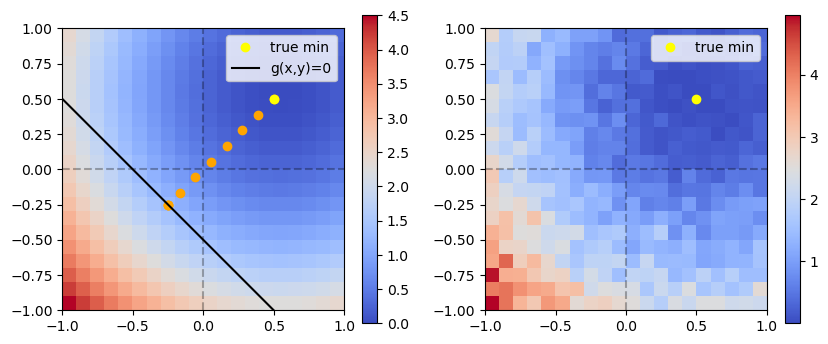

In [58]:
import matplotlib.cm as cm

# parameters
dx = 0.1     # spatial resolution
ub = 1       # upper bound
lb = -1      # lower bound
cx = 0.5     # x-coordinate of center
cy = 0.5   # y-coordintate of center
mx = 1
my = 1
const = -0.5
noise = 0.1  # noise level

x = np.arange(lb, ub, dx)
y = np.arange(lb, ub, dx)
X, Y = np.meshgrid(x, y)
detZ = detfun(np.array([X, Y]), cx, cy, mx, my, const)
stochZ = stochfun(np.array([X, Y]), cx, cy, noise)

# CMA-ES parameters
bounds = np.array([[lb, lb], [ub, ub]])
x0 = np.zeros(2)
sigma0 = 0.3
opts = {'maxfevals': 1000,
        'verb_filenameprefix':'exps/data/outcmaes-test/'}
betas = np.linspace(0, 2, 10)
solutions = []

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

for key, beta in enumerate(betas):
    xopt, es = cma.fmin2(detfun, x0, sigma0, args=(cx, cy, mx, my, const, beta), options=opts)
    ax[0].plot(xopt[0], xopt[1], 'o', color='orange')
    solutions.append(es)

im0 = ax[0].imshow(detZ, interpolation='none', origin='lower', cmap=cm.coolwarm, extent=(lb, ub, lb, ub))
im1 = ax[1].imshow(stochZ, interpolation='none', origin='lower', cmap=cm.coolwarm, extent=(lb, ub, lb, ub))
ax[0].plot(cx, cy, 'o', color='yellow', label='true min')
ax[0].plot(x, (const - x*mx) / my, color='black', label='g(x,y)=0')
ax[1].plot(cx, cy, 'o', color='yellow', label='true min')
ax[0].axhline(y = 0, linestyle='dashed', color='black', alpha=0.3)
ax[1].axhline(y = 0, linestyle='dashed', color='black', alpha=0.3)
ax[0].axvline(x = 0, linestyle='dashed', color='black', alpha=0.3)
ax[1].axvline(x = 0, linestyle='dashed', color='black', alpha=0.3)
ax[0].set_xlim(-1,1)
ax[0].set_ylim(-1,1)

_ = fig.colorbar(im0, orientation='vertical', shrink=1)
_ = fig.colorbar(im1, orientation='vertical', shrink=1)
ax[0].legend()
ax[1].legend()

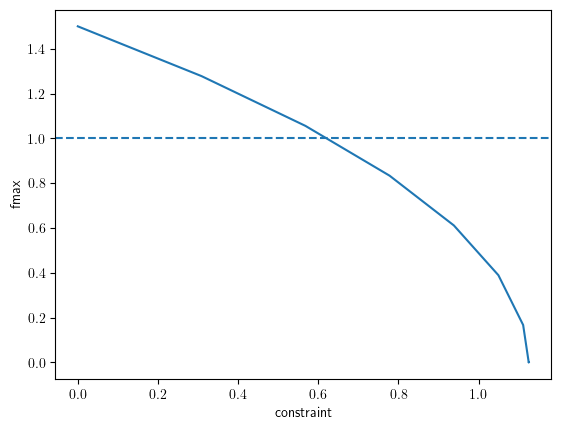

In [64]:
fig, ax = plt.subplots(1,1)

fopts = []
constr = []
fmax = 1

for key, beta in enumerate(betas):
    es = solutions[key]
    res = es.result
    fopts.append(res[1])
    constr.append(constraint(res[0], mx, my, const))

ax.plot(fopts, constr)
ax.set_ylabel('fmax')
ax.set_xlabel('constraint')
ax.axhline(y=fmax, linestyle='dashed')

# IR-EPr Pareto front

In [9]:
def get_data(dirname, whichf):
    paramfile = "params"
    path = '/home/tohme/.julia/dev/LLROpt/data/'
    params = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

    data = {}
    data_proc = {}
    ncpus = params["ncpus"]
    nbetas = params["nparams"]
    nparams_per_cpu = int(nbetas/ncpus)

    for cpukey in range(1, ncpus + 1):
        data_proc = json.load(open(path+'{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

        for i in range(1, nparams_per_cpu+1):
            keyb = (cpukey - 1) * nparams_per_cpu + i
            data[keyb] = data_proc[str(keyb)]

    return data, params

## $\min \{-IR + \beta EP\}$

In [223]:
edges = [(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
         (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]
input_edges = [(1,3), (2,4), (5,1), (6,2)]
on_ind = np.array([0,1,0,1,0,1])

G = nx.DiGraph()
for u, v, w in wedges_acc_lin:
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)]) for i in G.nodes()]

node_labels = {0: r'FU',
                1: r'NU',
                2: r'FBR',
                3: r'NBR',
                4: r'FBW',
                5: r'NBW'}

node_numbers = {0: r'1',
                1: r'2',
                2: r'3',
                3: r'4',
                4: r'5',
                5: r'6'}

input_labels = {(0,4):"cw",
                (0,2):"cr",
                (1,5):"cw",
                (1,3):"cr"}

figcirc, ax, G = plot.draw_circuit(wedges_acc,
                                   iedges, 
                                   node_labels=node_numbers, 
                                   input_labels=input_labels,
                                   bottom_set=[5,1,3],
                                   node_size=1000,
                                   node_color=node_color,
                                   title="IR_acc",
                                   dims=(5,2.8))

NameError: name 'wedges_acc_lin' is not defined

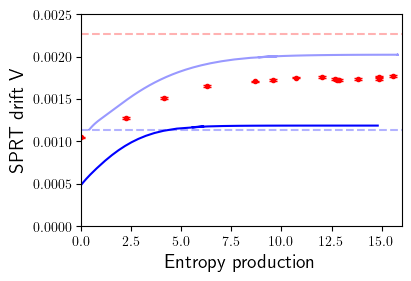

In [666]:
dirname_full = '20241107/ir-ep'
dirname_full = '20241206/ir-ep-finetune-from-20241107/'
dirname_acc = '20241204/1bs-ir-ep-acc'
dirname_acc2 = '20241203/2bs-ir-ep/test-forcing-konu-de'
ncpus = 32
nedges = 8
skipkeys = [1,2,3,4,5,6,7,9,10,11,12,13,15,17,20,23,29]
# skipkeys = []
figsize = (4,2.7)
color_full = "red"
color_acc = "blue"
data_full, params_full = get_data(dirname_full, "full")
data_acc, params_acc = get_data(dirname_acc, "acc")
data_acc2, params_acc2 = get_data(dirname_acc2, "acc")

irvals_full = [data_full[i][nedges] for i in range(1, params_full["nparams"]+1) if i not in skipkeys]
irvals_full_err = [data_full[i][nedges+2] for i in range(1, params_full["nparams"]+1) if i not in skipkeys]
epvals_full = [data_full[i][nedges+1] for i in range(1, params_full["nparams"]+1) if i not in skipkeys]

irvals_acc = [data_acc[i][nedges] for i in range(1, params_acc["nparams"]+1)]
epvals_acc = [data_acc[i][nedges+1] for i in range(1, params_acc["nparams"]+1)]
irvals_acc2 = [data_acc2[i][10] for i in range(1, params_acc2["nparams"]+1)]
epvals_acc2 = [data_acc2[i][10+1] for i in range(1, params_acc2["nparams"]+1)]
                   
plt.rcParams['text.usetex'] = True

figplot, ax = plt.subplots(1,1, layout='constrained', figsize=figsize)

ax.errorbar(epvals_full, irvals_full, yerr=irvals_full_err, marker='o', linestyle='none', capsize=3, color=color_full, markersize=3)
ax.plot(epvals_acc, irvals_acc, linestyle='solid', color=color_acc)
ax.plot(epvals_acc2, np.array(irvals_acc2), linestyle='solid', color=color_acc, alpha=0.4)

ax.set_ylim(0, 2.5e-3)
ax.set_xlim(0, 16)
ax.set_title("")
ax.set_ylabel("SPRT drift V", fontsize=14)
ax.set_xlabel("Entropy production", fontsize=14)

c = 5.6
dc = 0.56
kboff = 0.0888
konb = 5
kuon = 5
koffu = 5

kbon = 1e-5
koffb = 1e-5
kuoff = 1e-5
konu = 1e-5

D_full2b = ((dc/c)**2/2) * (c*kboff*kuon/(c*kboff+kuon))
ax.axhline(y=D_full2b, linestyle="dashed", color="red", alpha=0.3)
ax.axhline(y=D_full2b/2, linestyle="dashed", color="blue", alpha=0.3)

In [225]:
date = 20241204
dirname = '/home/tohme/phd/flython/plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('/home/tohme/phd/flython/plots/{}/ir-ep-acc-full.pdf'.format(date))

ir: 0.0004907733
ep: 0.024388282


/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


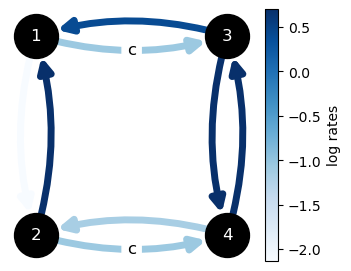

In [675]:
edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
ie = [(0,2), (1,3)]
weights = data_full[31][:8]
we = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
we[1][2] = -5
we[2][2] = -5
we[4][2] = -5
we[7][2] = -5
weights_acc = data_acc[31][:8]
we_acc = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights_acc)])

k = 1
weights_eq = data_full[k][:8]
we_eq = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights_eq)])
# we_eq[3][2] = -5
node_labels = dict(zip(range(4), range(1,5)))
input_labels = dict(zip(ie, ['c']*2))

weights_eq_acc = data_acc[1][:8]
we_eq_acc = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights_eq_acc)])
# we_eq_acc[1][2] = -5

fig, ax, G = plot.draw_circuit(we_eq_acc, ie, dims=(3.4,2.6), 
                               node_size=1000, 
                               node_labels=node_labels, 
                               input_labels=input_labels)
print('ir:', data_acc[k][8])
print('ep:', data_acc[k][9])



/tmp/ipykernel_99135/2490290473.py:36: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax1.plot(xhull, yhull, 'r-', lw=2,color="green")
/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(
/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(
/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(
/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab

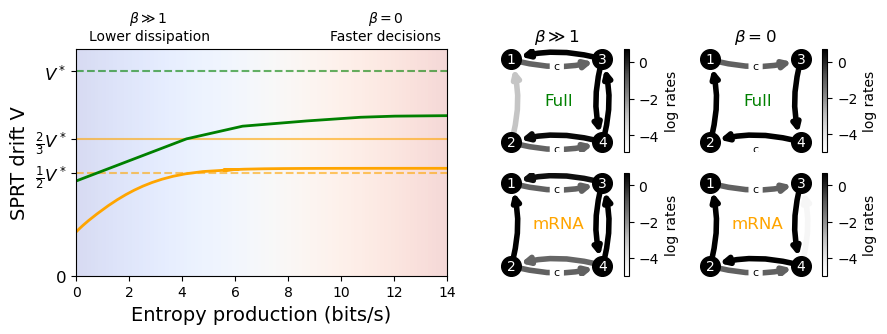

In [668]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
importlib.reload(plot)

# Create a figure
fig = plt.figure(figsize=(9, 3.5), layout="tight")

# Define the GridSpec with 1 row and 3 columns, and the right side having 2 rows
gs = gridspec.GridSpec(1, 3, width_ratios=[2.5, 1, 1])  # Left plot twice as wide

# Define a nested GridSpec for the right side with 2 rows
right_gs = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs[2])
mid_gs = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs[1])

# Create the large plot on the left
ax1 = fig.add_subplot(gs[0])

## Convex hull
xydata_ = np.stack((epvals_full, irvals_full), axis=1)
# mask = np.where(np.bitwise_and(xydata[:,0] > xlb, xydata[:,0] < xub))
# xydata_ = xydata[mask]
hull = ConvexHull(xydata_)
xhull = [xydata_[hull.vertices[i]][0] for i in range(-5,2)]
yhull = [xydata_[hull.vertices[i]][1] for i in range(-5,2)]

# ax1.errorbar(epvals_full, irvals_full, yerr=irvals_full_err, marker='o', linestyle='none', 
#              capsize=3, color="green", markersize=3)
ax1.plot(epvals_acc, irvals_acc, lw=2,linestyle='solid', color="orange")
ax1.set_ylim(0, 2.5e-3)
ax1.set_xlim(0, 14)
ax1.set_ylabel("SPRT drift V", fontsize=14)
ax1.set_xlabel("Entropy production (bits/s)", fontsize=14)
ax1.axhline(y=D_full2b/2, linestyle="dashed", color="orange", alpha=0.6)
ax1.axhline(y= 2*D_full2b/3, lw=1.5, linestyle="solid", color="orange", alpha=0.6)
ax1.axhline(y=D_full2b, linestyle="dashed", color="green", alpha=0.6)
ax1.plot(xhull, yhull, 'r-', lw=2,color="green")
ax1.set_yticks([0,D_full2b/2,2*D_full2b/3,D_full2b])
ax1.set_yticklabels([0, r"$\frac{1}{2}V^*$", r"$\frac{2}{3}V^*$", r"$V^*$"], fontsize=12)

ax1.text(0.5,2.6e-3,r"Lower dissipation", fontsize=10)
ax1.text(2,2.8e-3,r"$\beta \gg 1$", fontsize=10)
ax1.text(9.6,2.6e-3,r"Faster decisions", fontsize=10)
ax1.text(11.0,2.8e-3,r"$\beta = 0$", fontsize=10)
x = np.linspace(0, 14, 100)
y = np.linspace(0, 1, 100)
X, Y = np.meshgrid(x, y)
Z = X + Y  # This will create a simple gradient effect

# Use imshow to display the gradient as the background
ax1.imshow(Z, extent=[0, 14, 0, 1], origin='lower', aspect='auto', cmap='coolwarm', alpha=0.2)

# Create the first smaller plot on the right (top part)
ax2 = fig.add_subplot(right_gs[0])
ax2.set_title(r"$\beta = 0$")
ax2.text(-0.2,-0.1,"Full", color="green", fontsize=12)
_, _, G = plot.draw_circuit(we, ie, 
                            dims=(2,2), 
                            figax = (fig, ax2),
                            node_size=200, 
                            node_labels=node_labels, 
                            input_labels=input_labels,
                            arrsize=11,
                            edge_cmap=plt.cm.Grays,
                            arrwidth=4,
                            edgefsize=8,
                            nodefsize=10)

# Create the second smaller plot on the right (bottom part)
ax3 = fig.add_subplot(right_gs[1])
ax3.text(-0.4,-0.1,"mRNA", color="orange", fontsize=12)
_, _, G = plot.draw_circuit(we_acc, ie, 
                            dims=(2,2), 
                            figax = (fig, ax3),
                            node_size=200, 
                            node_labels=node_labels, 
                            input_labels=input_labels,
                            node_cmap=plt.cm.copper,
                            edge_cmap=plt.cm.Grays,
                            arrsize=11,
                            arrwidth=4,
                            edgefsize=8,
                            nodefsize=10)

# Create the second smaller plot on the right (top part)
ax4 = fig.add_subplot(mid_gs[0])
ax4.set_title(r"$\beta \gg 1$")
ax4.text(-0.2,-0.1,"Full", color="green", fontsize=12)
_, _, G = plot.draw_circuit(we_eq, ie, 
                            dims=(2,2), 
                            figax = (fig, ax4),
                            node_size=200, 
                            node_labels=node_labels, 
                            input_labels=input_labels,
                            node_cmap=plt.cm.copper,
                            edge_cmap=plt.cm.Grays,
                            arrsize=11,
                            arrwidth=4,
                            edgefsize=8,
                            nodefsize=10)

# Create the second smaller plot on the right (bottom part)
ax5 = fig.add_subplot(mid_gs[1])
ax5.text(-0.4,-0.1,"mRNA", color="orange", fontsize=12)
_, _, G = plot.draw_circuit(we_eq_acc, ie, 
                            dims=(2,2), 
                            figax = (fig, ax5),
                            node_size=200, 
                            node_labels=node_labels, 
                            input_labels=input_labels,
                            node_cmap=plt.cm.copper,
                            edge_cmap=plt.cm.Grays,
                            arrsize=11,
                            arrwidth=4,
                            edgefsize=8,
                            nodefsize=10)


# Adjust layout to avoid overlap
plt.tight_layout()

# Show the plot we_eq_acc
plt.show()

In [324]:
date = 20241206
dirname = '/home/tohme/phd/flython/plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('/home/tohme/phd/flython/plots/{}/ir-ep-with-opt-circuits.pdf'.format(date))

In [674]:
data_acc[32][:8]

[-1.0515872,
 -4.997476,
 -1.0515876,
 0.69897,
 -5.0,
 0.69897,
 0.69897,
 -4.8233194]

## $\min \{\langle T \rangle + \beta EP\}$

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


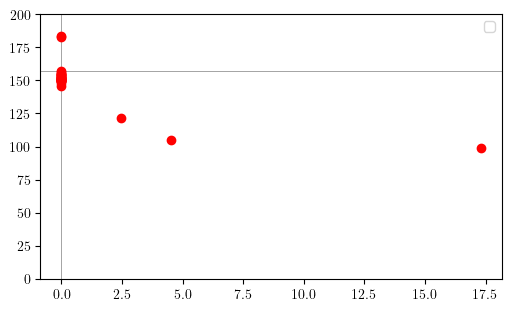

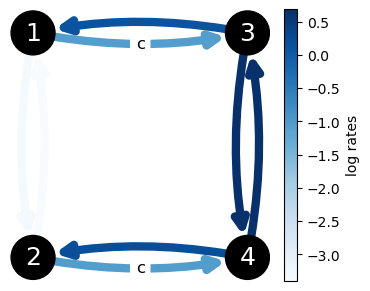

(<Figure size 360x280 with 2 Axes>,
 <Axes: >,
 <networkx.classes.digraph.DiGraph at 0x78b72e972190>)

In [ ]:
dirname = '20241204/dt-ep'
whichf = "full"
nedges = 8
k = 29
figsize = (5,3)
showlines = True
fig, ax, data = plot_data(None, color="red", figsize=figsize)
ax.legend()
# ax.set_xlim(0,20)
ax.set_ylim(0, 200)
weights = data[k][:nedges]

edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
iedges = [(0,2), (1,3)]
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
wedges_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights)])
on_ind = [0,1,0,1]
node_labels = dict(zip(range(4), range(1,5)))
input_labels = dict(zip(iedges, ['c']*2))
bottom_set = [1,3]
node_size=1000

Q = utils.build_mat(wedges_lin, iedges, 5.6)
pss = ctmc.P_ss(Q)
G = nx.DiGraph()
for u, v, w in wedges:
    G.add_edge(u, v, weight=w)

# node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]
node_color = np.zeros(4)

plot.draw_circuit(wedges, 
                iedges, 
                node_labels=node_labels, 
                input_labels=input_labels,
                bottom_set=bottom_set,
                node_size=node_size,
                node_color=node_color,
                #   title="2 binding sites",
                dims=(3.6,2.8))

In [143]:
dirname = '/home/tohme/phd/flython/plots/{}'.format(20241128)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig(dirname+'/dt-ep-three-epsilons.pdf')

In [86]:
fig.savefig('plots/optimal_circuit_4s_acc_beta0.pdf')

## $\min \{ \langle T \rangle + \beta Var(T) \}$

Text(0.5, 0, '$Var(T)$')

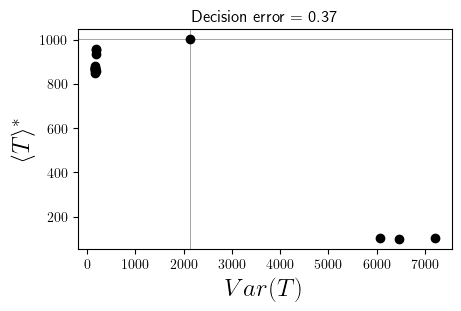

In [265]:
dirname = '20241127/dt-vart/test-e=0.37-k=2000-n=5000-maxiters=5000/'
k = 7
showlines = True
fig, ax, data = plot_ir_ep(None, color="black")

ax.axhline(y = data[k][8], linewidth=0.5, color="gray")
ax.axvline(x = data[k][9], linewidth=0.5, color="gray")
ax.set_xlabel("$Var(T)$")

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


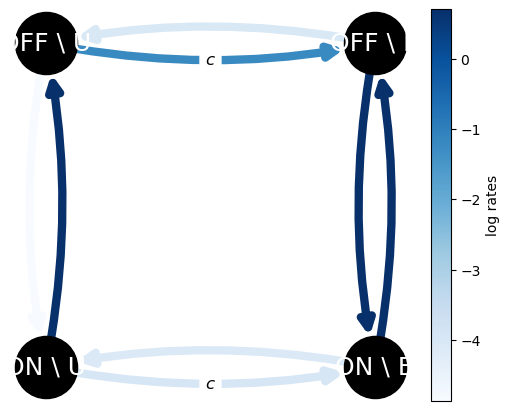

(<Figure size 500x400 with 2 Axes>,
 <Axes: >,
 <networkx.classes.digraph.DiGraph at 0x7c9d279ed850>)

In [266]:
logrates = data[k][:nedges]
edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
input_edges = [(0,2), (1,3)]
on_ind = np.array([0,1,0,1])
we = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates)])

plot.draw_circuit(we, input_edges)

# Modeling specificity with one binding site

### $IR_{mix}$ vs. threshold on $k_u^w/k_u^c \geq r$

### IR versus [wrong ligand] / [right ligand]

(0.0, 1.05)

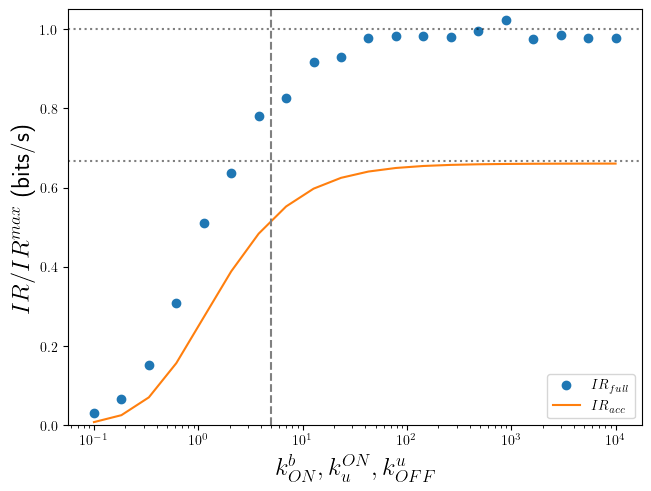

In [252]:
data_full = json.load(open('/home/tohme/.julia/dev/LLROpt/data/ir_full_scaling_output_20240725.json'))
data_acc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/ir_acc_scaling_output_20240725.json'))

nvals = len(data_full.keys())

xvals = np.logspace(-1, 4, 20)
# ir_full_pure = data["ir_full_pure"]
# ir_full_mix = data["ir_full_mix"]
# ir_acc_pure = data["ir_acc_pure"]
# ir_acc_mix = data["ir_acc_mix"]

fig, ax = plt.subplots(1,1, layout='constrained')

# ax.plot(xvals, ir_full_pure, 'o', color='C1', label=r"$IR_{f}^{pure}$")
# ax.plot(xvals, ir_full_mix, 'o', color='C2', label=r"$IR_{f}^{mix}$")

# ax.plot(xvals, ir_acc_pure, color='C1', label=r"$IR_{a}^{pure}$")
# ax.plot(xvals, ir_acc_mix, color='C2', label=r"$IR_{a}^{mix}$")
ax.plot(xvals, [data_full[str(i)] for i in range(1, nvals+1)], 'o', label=r"$IR_{full}$")
ax.plot(xvals, [2*data_acc[str(i)]/3 for i in range(1, nvals+1)], label=r"$IR_{acc}$")
ax.set_xlabel(r"$k_{ON}^b, k_{u}^{ON}, k_{OFF}^u$", fontsize=18)
ax.set_ylabel(r"$IR/IR^{max}$ (bits/s)", fontsize=18)
ax.axvline(x=5, linestyle='dashed', color='gray')
ax.axhline(y=1, linestyle='dotted', color='black', alpha=0.5)
ax.axhline(y=2/3, linestyle='dotted', color='black', alpha=0.5)
ax.legend()
ax.set_xscale('log')

ax.set_ylim(0, 1.05)

In [253]:
fig.savefig("plots/ir_limit_konb_kuon_koffu_large_notrescaled_20240725.pdf")

### maximizing $DR + \beta \epsilon$

In [3]:
def f(x,g):
    a = 1/g
    b = 1-a/(1-a)
    if a >= 1/2:
        return (2*a-1)/(1-a)**2
    else:
        return (1-a)*a**(-1/(1-a))*np.sin(np.pi*a/(1-a))*x**b/np.pi

In [4]:
# dirname = '20241004/full'
# dirname = '20241111/ir-epsilon'
# dirname = '20241113/ir-dr'
# dirname = '20241116/ir-dr-from-20241113/cmaes'
# dirname = '20241114/ir-epsilon-hernan/gen2'
# dirname = '20241116/dr-epsilon-from-20241114/cmaes'
# dirname = '20241114/dr-epsilon'
# dirname = '20241118/dr-epsilon-hernan/bigsweep-cmaes-C-pn'
# whichf = "full"

In [ ]:
whichf = "acc"
k, kg, kw = (1, 3, 2)
ginds, winds = [2], [1]
# ylb, yub = -4e-5, 18.5e-4
# xlb, xub = 9.5, 13.7        # low omega

ylb, yub = -4e-5, 18.5e-4
xlb, xub = 9.5, 13.7        # medium omega

# ylb, yub = None, None
# xlb, xub = None, None
showbound = True
showlines = False
showlegend = True
legend_loc = 'upper right' 
ylab = r"$DR^*$"
xlab = r"$- \log(\varepsilon^*)$"
fill = "full"
line = "none"
msize = 3
figsize = (5,3.5)

In [340]:
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
importlib.reload(plot)

def plot_pareto(figax, plotcirc=False, color=None):
    paramfile = "params"
    path = '/home/tohme/.julia/dev/LLROpt/data/'
    params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

    data_acc = {}
    data_acc_proc = {}
    ncpus = params_acc["ncpus"]
    nbetas = params_acc["nparams"]
    betas = params_acc["betas"]
    gammas = params_acc["gammas"]
    wvals = params_acc["wvals"]
    nparams_per_cpu = int(nbetas/ncpus)

    a = 3e-3        # um
    D_tf = 7.4      # um^2/s
    D_cplx = 0.1    # um^2/s
    cr = 5.6         # um^-3
    dc = 0.1 * cr
    dl_tf = 4*a*D_tf
    ub = 5
    lb = 1e-5

    g = gammas[kg-1]
    w = wvals[kw-1]
    cw = w*cr
    x = cr / (cr+cw)

    max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)
    tau = (1/(1+w))*(1/(cr*dl_tf)+(1+w/g)/5)
    max_ir_mix = 0.5 * (dc**2/(cr**2 + f(x,g)*(cr+cw)**2))/tau

    for cpukey in range(1, ncpus + 1):
        data_acc_proc = json.load(open(path+'{}/ir_{}_mix_vs_pure_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

        for i in range(1, nparams_per_cpu+1):
            keyb = (cpukey - 1) * nparams_per_cpu + i
            data_acc[str(keyb)] = data_acc_proc[str(keyb)]

    # plt.rcParams['text.usetex'] = True

    if figax is None:
        figplot, ax = plt.subplots(1,1, layout='constrained', figsize=figsize)
    else:
        figplot, ax = figax

    colors = ['C{}'.format(i) for i in range(len(gammas))]
    markers = ['d','^','o']
    node_color = ""
    epvals = np.zeros((len(gammas), nbetas))
    cmap = plt.colormaps["viridis"]

    if whichf == "acc":
        epindex = 10
    else:
        epindex = 12

    for i in ginds:
        gamma = gammas[i]
        for j in winds:

            keyg = str(i+1)
            keyw = str(j+1)

            xopt = np.array([data_acc[str(k)][keyg][keyw][:8] for k in np.arange(1, nbetas+1, 1)])
            ir_acc_mix = np.array([data_acc[str(k)][keyg][keyw][8] for k in np.arange(1, nbetas+1, 1)])
            ir_acc_pure = np.array([data_acc[str(k)][keyg][keyw][9] for k in np.arange(1, nbetas+1, 1)])
            epvals[i] = np.array([data_acc[str(k)][keyg][keyw][epindex] for k in np.arange(1, nbetas+1, 1)])

            for x in range(nbetas - 1):
                if color is None:
                    col = cmap(epvals[i,x])
                else:
                    col = color

                ax.plot([ir_acc_mix[x], ir_acc_mix[x+1]],
                        [ir_acc_pure[x], ir_acc_pure[x+1]],
                        marker=markers[i], 
                        fillstyle=fill,
                        color=col, 
                        linestyle=line, 
                        markersize=msize)


            ax.set_ylabel(ylab, fontsize=18)
            ax.set_xlabel(xlab, fontsize=22)
            irvals = np.linspace(0, 2e-3, 50)

        if showbound:
            ax.axvline(x=np.log2(gamma**2/w), linestyle='dashed', color='gray', alpha=0.6)
            ax.axvline(x=np.log2(gamma/w), linestyle='dotted', color='gray', alpha=0.6)
            ax.axhline(y=0.001186, linestyle='solid', color='gray', alpha=0.6)

    _=ax.set_title(r"$\omega = c_w/c_r$ = {}".format(w), fontsize=20)

    xopt_acc = data_acc[str(k)][str(kg)][str(kw)][:8]
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = xopt_acc
    logrates2 = [kuoff+np.log10(g), kboff+np.log10(cw), kbon+np.log10(cw), kuon+np.log10(g), 
            konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]

    edges = [(4,0), (0,4), (1,5), (5,1), (0,1), (0,2), (1,3),
            (1,0), (2,0), (2,3), (3,1), (3,2), (4,5), (5,4)]
    wedges_acc = [(u,v,w) for ((u,v), w) in zip(edges, logrates2)]
    wedges_acc_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])

    iedges = [(0,2), (1,3)]
    on_ind = np.array([0,1,0,1,0,1])
    Q = utils.build_mat(wedges_acc_lin, iedges, cr)
    pss = ctmc.P_ss(Q)
    pc = sum(pss[[0]])

    # h1 = mpatches.Patch(color=colors[j])  
    # wlabels = list(zip(*[(mpatches.Patch(color=colors[j]), 'w = {}'.format(w)) for (j,w) in enumerate(wvals)]))
    gammalabels = list(zip(*[(Line2D([0], [0], linestyle='none', fillstyle='none',marker=markers[i], color="black"),r"$\gamma = {}$".format(round(g, 1))) for (i,g) in enumerate(gammas)]))

    # ax.legend(wlabels[0]+gammalabels[0], wlabels[1]+gammalabels[1], loc='lower right')
    if showlegend:
        ax.legend(gammalabels[0], gammalabels[1], loc='upper right', fontsize=8)
        ax.legend((Line2D([0], [0], linestyle='dotted', color='gray'),
                Line2D([0], [0], linestyle='dashed', color='gray'),
                Line2D([0], [0], linestyle='solid', color='gray')),
                (r"$\log(\gamma/\omega)$",r"$\log(\gamma^2/\omega)$", r"$\frac{1}{4\tau}(\frac{dc}{c})^2$"), loc=legend_loc) # (0.5,0.1)
    ax.set_ylim(ylb, yub)
    ax.set_xlim(xlb, xub)

    if showlines:
        ax.axhline(y = data_acc[str(k)][str(kg)][str(kw)][9], linewidth=0.5, color="gray")
        ax.axvline(x = data_acc[str(k)][str(kg)][str(kw)][8], linewidth=0.5, color="gray")

    if color is None:
        if figax is None:
            cb = figplot.colorbar(plt.cm.ScalarMappable(norm=Normalize(0,max(epvals.flatten())), cmap=cmap),
                                ax=ax)

            cb.set_label(label="$EP$ rate", fontsize=14)

    G = nx.DiGraph()
    for u, v, w in wedges_acc_lin:
        G.add_edge(u, v, weight=w)

    if node_color != "black":
        node_color = [np.log(pss[int(i)]) for i in G.nodes()]

    node_labels = {0: r'FU',
                    1: r'NU',
                    2: r'FBR',
                    3: r'NBR',
                    4: r'FBW',
                    5: r'NBW'}

    node_numbers = {0: r'1',
                    1: r'2',
                    2: r'3',
                    3: r'4',
                    4: r'5',
                    5: r'6'}

    input_labels = {(0,4):"cw",
                    (0,2):"cr",
                    (1,5):"cw",
                    (1,3):"cr"}

    if plotcirc:
        figcirc, axcirc, G = plot.draw_circuit(wedges_acc,
                                        iedges, 
                                        node_labels=node_numbers, 
                                        input_labels=input_labels,
                                        bottom_set=[5,1,3],
                                        node_size=1000,
                                        node_color=node_color,
                                        title="IR_acc",
                                        dims=(5,2.8))
    else:
        figcirc = None
    
    return figplot, ax, xopt_acc, logrates2, data_acc, params_acc

/tmp/ipykernel_99135/1831240371.py:47: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax.plot(xhull, yhull, 'r-', lw=2,color=cols[id])


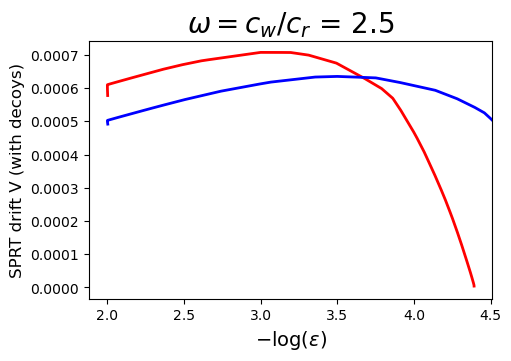

In [ ]:
plt.rcParams["text.usetex"] = False

dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-A-pn-simfull-200k-fcalls-lownoise'
whichf = "full"
msize = 0
showbound = False
figplot, ax, _, _, dataA, paramsA = plot_pareto(None, color="red")      # local optimization
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-B-pn-simfull-100k-fcalls-lownoise'
figplot, ax, _, _, dataB, paramsB = plot_pareto((figplot, ax), color="blue")
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-C-pn-simfull-200k-fcalls-lownoise'
figplot, ax, _, _, dataC, paramsC = plot_pareto((figplot, ax), color="green")

cols = ["red", "blue", "green", "red", "blue", "green"]
# rx = [(5,63), (5,50), (12,18)] # low omega
rx = [(5,45), (5,38), (12,18)]
msize = 5
ax.set_title(r"$\omega = 2.5$", fontsize=14)

key_g = 3
key_w = 2
g = paramsA["gammas"][key_g-1]
w = paramsA["wvals"][key_w-1]
dlb, dub = np.log2(g/w), np.log2(g**2/w)
nbetas = 512

## Convex hull
for (id, data) in enumerate([dataA, dataB, dataC]):
    drvals = np.array([data[str(k)][str(key_g)][str(key_w)][8] for k in np.arange(1, nbetas+1, 1)])
    epsvals = np.array([data[str(k)][str(key_g)][str(key_w)][9] for k in np.arange(1, nbetas+1, 1)])

    xydata = np.stack((drvals, epsvals), axis=1)
    mask = np.where(np.bitwise_and(xydata[:,0] > dlb, xydata[:,0] < dub))
    xydata_ = xydata[mask]
    hull = ConvexHull(xydata_)
    xhull = [xydata_[hull.vertices[i]][0] for i in range(rx[id][0], rx[id][1])]
    yhull = [xydata_[hull.vertices[i]][1] for i in range(rx[id][0], rx[id][1])]

    if id == 2:
        ax.scatter(drvals[-3], epsvals[-3], s=110, marker='o', color=cols[id], 
                   facecolors="none", linestyle='-', lw=2)
    else:
        ax.plot(xhull, yhull, 'r-', lw=2,color=cols[id])

k, kg, kw = (1, 1, 2)
ginds, winds = [0], [1]
# dirname = '20241206/dr-epsilon/cmaes-A-pn-full/'
msize = 0
dirname = '20241120/dr-epsilon/cmaes-A-pn-full/'
whichf = "full"
figplot, ax, _, _, datafA, paramsfA = plot_pareto((figplot, ax), color="red")      # local optimization
dirname = '20241120/dr-epsilon/cmaes-B-pn-full'
figplot, ax, _, _, datafB, paramsfB = plot_pareto((figplot, ax), color="blue")
dirname = '20241120/dr-epsilon/cmaes-C-pn-full'
figplot, ax, _, _, datafC, paramsfC = plot_pareto((figplot, ax), color="green")

ax.get_legend().remove()
# ax.axvline(x=dlb, linestyle='dotted', color='black', alpha=0.5, label=r"$\log (\gamma / \omega)$")
# ax.axvline(x=dub, linestyle='dashed', color='black', alpha=0.5, label=r"$\log (\gamma^2 / \omega)$")
# ax.legend(loc=(0.15, 0.07), fontsize=12)
ax.set_ylabel("SPRT drift V (with decoys)", fontsize=12)

ax.set_xlabel(r"$-\log(\varepsilon)$", fontsize=14)
# ax.text(10, 2.1e-3, r"$\beta = 0$", fontsize=10)
# ax.text(9.6, 1.95e-3, "Faster decisions", fontsize=10)
# ax.text(13, 2.1e-3, r"$\beta \gg 1$", fontsize=10)
# ax.text(12.8,1.95e-3,"Lower errors", fontsize=10)
x = np.linspace(9.5, 14, 100)
y = np.linspace(-1e-2, 1e-2, 100)
X, Y = np.meshgrid(x, y)
Z = X + Y  # This will create a simple gradient effect

# Use imshow to display the gradient as the background
ax.imshow(Z, extent=[9.5, 14, -1e-2, 1], origin='lower', aspect='auto', cmap='PiYG', alpha=0.2)

# rx = [(1,12), (1,11), (4,7)]
rx = [(2,14), (-5,6), (1,5)]
msize = 5

# key_g = 1
# key_w = 2
# g = paramsfA["gammas"][key_g-1]
# w = paramsfA["wvals"][key_w-1]
# dlb, dub = np.log2(g/w), np.log2(g**2/w)
# nbetas = 32

# ## Convex hull
# for (id, data) in enumerate([datafA, datafB, datafC]):
#     drvals = np.array([data[str(k)][str(key_g)][str(key_w)][8] for k in np.arange(1, nbetas+1, 1)])
#     epsvals = np.array([data[str(k)][str(key_g)][str(key_w)][9] for k in np.arange(1, nbetas+1, 1)])

#     xydata = np.stack((drvals, epsvals), axis=1)
#     mask = np.where(np.bitwise_and(xydata[:,0] > dlb, xydata[:,0] < dub))
#     xydata_ = xydata[mask]
#     hull = ConvexHull(xydata_)
#     xhull = [xydata_[hull.vertices[i]][0] for i in range(rx[id][0], rx[id][1])]
#     yhull = [xydata_[hull.vertices[i]][1] for i in range(rx[id][0], rx[id][1])]

#     if id == 2:
#         ax.scatter(drvals[-3], epsvals[-3], s=110, marker='o', color=cols[id], 
#                    facecolors="none", linestyle='dashed', lw=2)
#     else:
#         ax.plot(xhull, yhull, 'r--', lw=2,color=cols[id])

In [327]:
date = 20241209
dirname = '/home/tohme/phd/flython/plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

figplot.savefig('/home/tohme/phd/flython/plots/{}/dr-epsilon-clean-loww.pdf'.format(date))

In [111]:
### mean burst time
edges = [(4,0), (0,4), (1,5), (5,1), (0,1), (0,2), (1,3),
        (1,0), (2,0), (2,3), (3,1), (3,2), (4,5), (5,4)]
wedges_acc = [(u,v,w) for ((u,v), w) in zip(edges, rates2)]
wedges_acc_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, rates2)])

iedges = [(0,2), (1,3)]
on_ind = np.array([0,1,0,1,0,1])
tauon, tauoff = ctmc.mean_fpt_part(wedges_acc_lin, iedges, 5.6, on_ind)
tauon + tauoff

12.091142136640633

In [131]:
figplot.savefig('/home/tohme/phd/flython/plots/20241120/dr_epsilon_hernan_de_localsearch_ABC_loww.pdf')

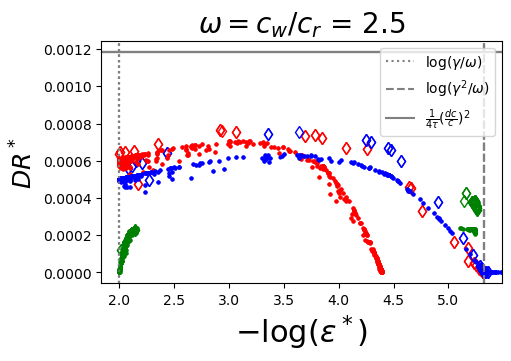

In [938]:
k, kg, kw = (1, 1, 2)
ginds, winds = [0], [1]
# ylb, yub = -4e-5, 12.5e-4
# xlb, xub = 1.5, 5.8
ylb, yub = None, None
xlb, xub = None, None
showbound = True
showlines = False
showlegend = True
legend_loc = 'upper right'
ylab = r"$DR^*$"
xlab = r"$- \log(\varepsilon^*)$"
figsize = (5,3.5)
fill = "none"
msize = 6

# dirname = '20241114/dr-epsilon'
dirname = '20241206/dr-epsilon/cmaes-A-pn-full/'
whichf = "full"
figplot, ax, rates1, rates2, _, _ = plot_pareto(None, color="red")      # local optimization
dirname = '20241206/dr-epsilon/cmaes-B-pn-full'
figplot, ax, _, _, _, _ = plot_pareto((figplot, ax), color="blue")
dirname = '20241206/dr-epsilon/cmaes-C-pn-full'
figplot, ax, _, _, _, _ = plot_pareto((figplot, ax), color="green")

# ax.text(3, 8.5e-4, "A", color="red", fontsize=20)
# ax.text(4.2, 8e-4, "B", color="blue", fontsize=20)
# ax.text(5.1, 4.5e-4, "C", color="green", fontsize=20)

# ax.text(10.5, 12.5e-4, "A", color="red", fontsize=20)
# ax.text(12, 14e-4, "B", color="blue", fontsize=20)
# ax.text(13, 7.5e-4, "C", color="green", fontsize=20)

k, kg, kw = (1, 3, 2)
ginds, winds = [2], [1]
fill = "full"
msize = 2

dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-A-pn-simfull-200k-fcalls-lownoise'
whichf = "full"
figplot, ax, rates1, rates2, _, _ = plot_pareto((figplot, ax), color="red")      # local optimization
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-B-pn-simfull-100k-fcalls-lownoise'
figplot, ax, _, _, _, _ = plot_pareto((figplot, ax), color="blue")
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-C-pn-simfull-200k-fcalls-lownoise'
figplot, ax, _, _, _, _ = plot_pareto((figplot, ax), color="green")

In [125]:
figplot.savefig('/home/tohme/phd/flython/plots/20241120/dr_epsilon_full_hernan_de_localsearch_ABC_loww.pdf')

### Clustering the solutions

In [984]:
def plot_clusters(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    # Black removed and is used for noise instead.
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    # The probability of a point belonging to its labeled cluster determines
    # the size of its marker
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    for k, col in zip(unique_labels, colors):
        if k == -1:
            # Black used for noise.
            col = [0, 0, 0, 1]

        class_index = np.where(labels == k)[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

    return ax

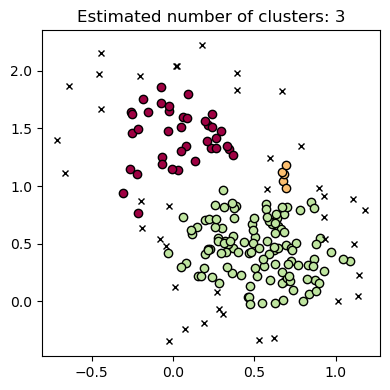

In [931]:
from sklearn.cluster import HDBSCAN
from sklearn.manifold import TSNE

rng = np.random.default_rng()

noise = 0.3

x1 = rng.normal(0,    noise,  50)
y1 = rng.normal(1.5,  noise,  50)
z1 = rng.normal(-2,   noise,  50)
w1 = rng.normal(0.5,  noise,  50)

x2 = rng.normal(0.5,  noise,  50)
y2 = rng.normal(0.5,  noise,  50)
z2 = rng.normal(0.5,  noise,  50)
w2 = rng.normal(0.5,  noise,  50)

x3 = rng.normal(0.5,  noise,  50)
y3 = rng.normal(0.5,  noise,  50)
z3 = rng.normal(1.5,  noise,  50)
w3 = rng.normal(1.5,  noise,  50)

x4 = rng.normal(0.5,  noise,  50)
y4 = rng.normal(0.5,  noise,  50)
z4 = rng.normal(-1.5,  noise,  50)
w4 = rng.normal(-1.5,  noise,  50)

x = np.concatenate((x1, x2, x3, x4))
y = np.concatenate((y1, y2, y3, y4))
z = np.concatenate((z1, z2, z3, z4))
w = np.concatenate((w1, w2, w3, w4))

X2 = np.stack((x,y), axis=1)
X4 = np.stack((x,y,z,w), axis=1)

hdb2d = HDBSCAN()
hdb2d.fit(X2)

plot(X2, hdb2d.labels_)

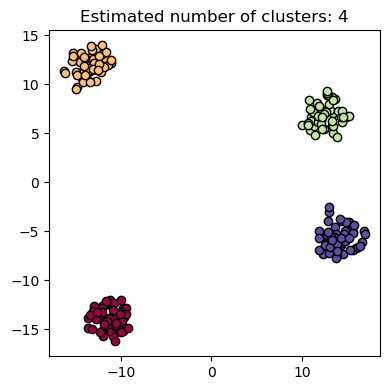

In [935]:
X4_embedded = TSNE(n_components=2, learning_rate='auto',
                    init='random', perplexity=30).fit_transform(X4)

hdb4d = HDBSCAN()
hdb4d.fit(X4_embedded)

plot(X4_embedded, hdb4d.labels_)

### maximizing $IR + \beta DR$

In [76]:
# dirname = '20241116/ir-dr-from-20241113/cmaes'
# dirname = '20241113/ir-dr'
# dirname = '20241004/full'
whichf = "full"
k, kg, kw = (20, 1, 1)
ginds, winds = [0], [0]
ylb, yub = None, None
xlb, xub = None, None
# xlb, xub = 2e-4, 7.5e-4
# ylb, yub = 5e-4, 15e-4
showlegend = False
showlines = False
showbound = True
legend_loc = 'center right'
ylab = r"$IR^*$"
xlab = r"$DR^*$"
fill = "full"

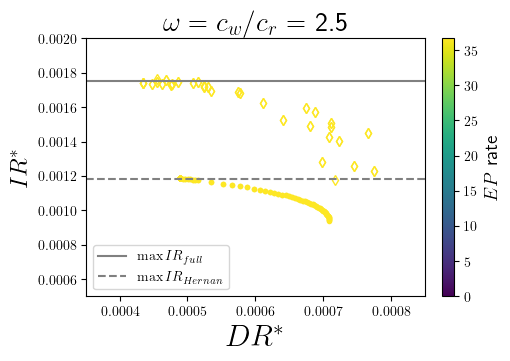

In [139]:
dirname = '20241125/ir-dr-hernan-p'
whichf = "acc"
k, kg, kw = (32, 3, 2)
ginds, winds = [2], [1]
xlb, xub = 3.5e-4, 8.5e-4
ylb, yub = 5e-4, 20e-4
# ylb, yub = None, None
# xlb, xub = None, None
showlines = False
showbound = False
msize=3
marker='o'
fill = "full"
fig, ax, _, _ = plot_pareto(None)

dirname = '20241120/ir-dr/g10-w2.5'
whichf = "full"
k, kg, kw = (32, 1, 1)
ginds, winds = [0], [0]
msize = 5
fill = "none"
fig, ax, _, _ = plot_pareto((fig, ax))
ax.axhline(y=0.00175, linestyle="solid", color="gray", label=r"$\max IR_{full}$")
ax.axhline(y=0.001185, linestyle="dashed", color="gray", label=r"$\max IR_{Hernan}$")
ax.legend(loc='lower left')

In [140]:
dirname = '/home/tohme/phd/flython/plots/20241126'

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig(dirname+'/ir-dr-full-hernan.pdf')

### Comparing fake IR_full to IR_acc

Text(0, 0.5, '$IR^*$')

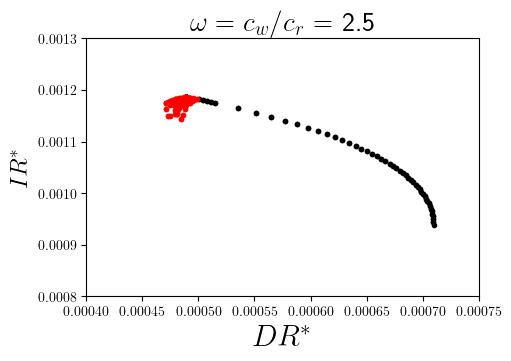

In [ ]:
# dirname = '20241125/ir-dr-hernan/coarse-sweep-1-alg=de-start=MGR-lg=global-whichf=simfull-maxiters=3000-sigma=3e-5-N=3000-nparams=1'
# dirname = '20241125/ir-dr-hernan/bigsweep-de-global-MGR-p-simfull-20k-fcalls-1-param-noise-2e-5-vhires'
# dirname = '20241125/ir-dr-hernan/bigsweep-cmaes-global-prevsim-p-simfull-4k-fcalls-1-param-noise-2.5e-6-hires'

# dirname = '20241125/ir-dr-hernan/coarse-sweep-1-alg=de-start=MGR-lg=global-whichf=simfull-maxiters=3000-sigma=3e-5-N=3000-nparams=1'
# dirname = '20241125/ir-dr-hernan/prevbeta-alg=cmaes-start=MGR-lg=global-whichf=simfull-maxiters=10-sigma=1e-5-N=1-nparams=1'
# dirname = '20241113/ir-dr'
dirname = '20241125/ir-dr-hernan-p'
whichf = "acc"
k, kg, kw = (20, 3, 2)
ginds, winds = [2], [1]
xlb, xub = 3.5e-4, 8.5e-4
ylb, yub = 5e-4, 20e-4
ylb, yub = None, None
xlb, xub = None, None
showlines = False
showbound = False
showlegend = False
msize=3
marker='o'
fill = "full"
fig, ax, _, _, figcirc = plot_pareto(None, False, color="black")
ax.set_title("")
ax.set_title("1000 out-of-bounds points around the IR-optimum", fontsize=12)
# ax.set_title("Subset of within-bounds points")

dirname = '20241123/test-point-cloud'
whichf = "full"
k, kg, kw = (1, 1, 1)
ginds, winds = [2], [0]
showlines = False
xlb, xub = 4e-4, 7.5e-4
ylb, yub = 8e-4, 13e-4
fig, ax, _, _, _ = plot_pareto((fig, ax), False, color="red")
# ax.set_title("CV = 0.13\%", fontsize=18)
ax.set_xlabel(r"$DR^*$")
ax.set_ylabel(r"$IR^*$")

In [228]:
import os
dirname = '/home/tohme/phd/flython/plots/20241127'

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('/home/tohme/phd/flython/plots/20241127/point-cloud-mgr-oob.pdf')
# figcirc.savefig('/home/tohme/phd/flython/plots/20241127/ir-dr-hernan-far-circuit.pdf')

### Special circuits

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


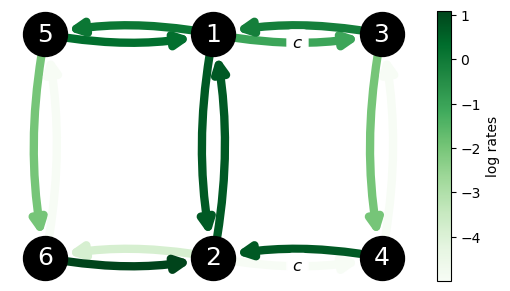

In [61]:
# circuit A
importlib.reload(plot)

edges = [(4,0), (0,4), (1,5), (5,1), (0,1), (0,2), (1,3),
            (1,0), (2,0), (2,3), (3,1), (3,2), (4,5), (5,4)]
input = [(0,2), (1,3)]
on_ind = np.array([0,1,0,1,0,1])
idist = np.ones(6) / 6
logratesA = [1.2825698,
          0.09454083567823801,
          0.09454083567823801,
          1.46107602,
          -4.9898477,
          -1.0515872,
          -1.0515872,
          0.69897,
          0.2825698,
          0.69897,
          0.46107602,
          -4.999996,
          0.69897,
          -4.999996]
logratesB = [1.6989699,
            0.09454083567823801,
            -3.853808964321762,
            1.54783356,
            -4.989879,
            -1.0515872,
            -4.999937,
            0.69897,
            0.6989699,
            0.69896984,
            0.54783356,
            -4.9945397,
            0.69896984,
            -4.9945397]
logratesC = [0.2695346886720376,
            0.09453593567823804,
            -3.853656964321762,
            1.0969087786720375,
            0.6989517,
            -1.0515921,
            -4.999785,
            0.69896877,
            -0.12840532,
            -1.9895186,
            0.69896877,
            -4.9985023,
            -1.9895186,
            -4.9985023]

whichc = "C"

if whichc == "A":
    logrates = logratesA
if whichc == "B":
    logrates = logratesB
if whichc == "C":
    logrates = logratesC

we = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates)])
we_lin = np.array([(u-1,v-1,10**r) for ((u,v),r) in zip(edges, logrates)])
Q = utils.build_mat(we_lin, input, c)
pss = ctmc.P_ss(Q)
node_color = [np.log(pss[int(i)]) for i in [0,1,2,3,4,5]]

node_numbers = {0: r'1',
                    1: r'2',
                    2: r'3',
                    3: r'4',
                    4: r'5',
                    5: r'6'}

figA, axA, graphA = plot.draw_circuit(we, 
                    input_edges=input, 
                    bottom_set=[5,1,3],
                    node_size=1000,
                    input_labels = None,
                    node_labels=node_numbers,
                    node_color="black",
                    edge_cmap=plt.cm.Greens,
                    # title="Circuit {}".format(whichc),
                    dims=(5,2.8))

In [62]:
import os
dirname = '/home/tohme/phd/flython/plots/20241126'

if not os.path.exists(dirname):
    os.makedirs(dirname)

figA.savefig('{}/circuitC.pdf'.format(dirname))

## No activation

In [55]:
dirname = '20241011/full'
whichf = "full"
k, kg, kw = (15, 2, 1)
xlim, ylim = (3e-3, 3e-3)
node_color = ""

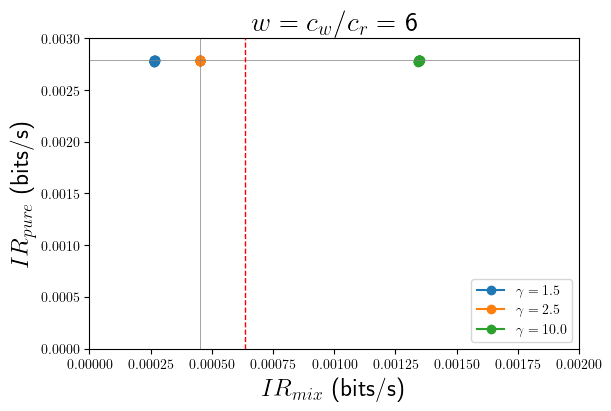

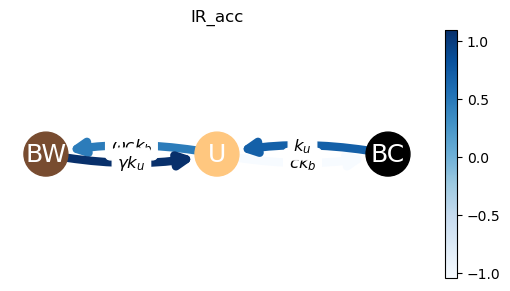

In [56]:
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
importlib.reload(plot)

path = '/home/tohme/.julia/dev/LLROpt/data/'
params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

data_acc = {}
data_acc_proc = {}
ncpus = params_acc["ncpus"]
nbetas = params_acc["nparams"]
betas = params_acc["betas"]
gammas = params_acc["gammas"]
wvals = params_acc["wvals"]
nparams_per_cpu = int(nbetas/ncpus)

winds = [kw-1]
g = gammas[kg-1]
w = wvals[kw-1]
cw = w*cr
x = cr/(cw+cr)
tau = (1/(1+w))*(1/(cr*dl_tf)+(1+w/g)/5)
max_ir_mix = 0.5 * (dc**2/(cr**2 + f(x,g)*(cr+cw)**2))/tau

for cpukey in range(1, ncpus + 1):
    data_acc_proc = json.load(open(path+'{}/ir_{}_mix_vs_pure_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

    for i in range(1, nparams_per_cpu+1):
        keyb = (cpukey - 1) * nparams_per_cpu + i
        data_acc[str(keyb)] = data_acc_proc[str(keyb)]

max_irpure = data_acc[str(1)][str(kg)][str(kw)][3]

plt.rcParams['text.usetex'] = True

fig, ax = plt.subplots(1,1, layout='constrained', figsize=(6,4))

colors = ['C{}'.format(i) for i in range(len(gammas))]

for (i, gamma) in enumerate(gammas):
    for j in winds:

        keyg = str(i+1)
        keyw = str(j+1)

        xopt = np.array([data_acc[str(k)][keyg][keyw][:2] for k in np.arange(1, nbetas+1, 1)])
        ir_acc_mix = np.array([data_acc[str(k)][keyg][keyw][2] for k in np.arange(1, nbetas+1, 1)])
        ir_acc_pure = np.array([data_acc[str(k)][keyg][keyw][3] for k in np.arange(1, nbetas+1, 1)])

        ax.plot( ir_acc_mix, ir_acc_pure, color=colors[i], marker='o', linestyle='none', markersize=6)

        ax.set_ylabel(r"$IR_{pure}$ (bits/s)", fontsize=18)
        ax.set_xlabel(r"$IR_{mix}$ (bits/s)", fontsize=18)
        irvals = np.linspace(0, 2e-3, 50)

h1 = mpatches.Patch(color=colors[j])  
wlabels = list(zip(*[(mpatches.Patch(color=colors[j]), 'w = {}'.format(w)) for (j,w) in enumerate(wvals)]))
gammalabels = list(zip(*[(Line2D([0], [0], color=colors[i], marker='o'),r"$\gamma = {}$".format(round(g, 1))) for (i,g) in enumerate(gammas)]))
ax.legend(wlabels[0]+gammalabels[0], wlabels[1]+gammalabels[1], loc='lower right')
ax.legend(gammalabels[0], gammalabels[1], loc='lower right')
ax.set_ylim(0, 3e-3)
ax.set_xlim(0, 2e-3)
ax.axhline(y = data_acc[str(k)][str(kg)][str(kw)][3], linewidth=0.5, color="gray")
ax.axvline(x = data_acc[str(k)][str(kg)][str(kw)][2], linewidth=0.5, color="gray")

ax.axvline(x = max_ir_mix, linewidth=1, color="red", linestyle="dashed")
# ax.axhline(y = ir_full_pure[k], linewidth=1, color="gray", linestyle="dashed")
# ax.axvline(x = ir_full_mix[k], linewidth=1, color="gray", linestyle="dashed")
_=ax.set_title(r"$w = c_w/c_r$ = {}".format(w), fontsize=20)
# ax.axvline(x=dcr_mle)

# plot circuit
importlib.reload(plot)

a = 3e-3        # um
D_tf = 7.4      # um^2/s
D_cplx = 0.1    # um^2/s
cr = 5.6         # um^-3
dc = 0.1 * cr
cw = w * cr
dl_tf = 4*a*D_tf
ub = 5
lb = 1e-5
max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)

xopt_acc = data_acc[str(k)][str(kg)][str(kw)][:2]
kb, ku = xopt_acc
logrates2 = [kb, ku, kb+np.log10(cw), ku+np.log10(g)]

edges = [(0,1),(1,0),(0,2),(2,0)]
wedges_acc = [(u,v,w) for ((u,v), w) in zip(edges, logrates2)]
wedges_acc_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])

iedges = [(0,1)]
on_ind = np.array([0,1,1])
Q = utils.build_mat(wedges_acc_lin, iedges, cr)
pss = ctmc.P_ss(Q)
pc = sum(pss[[0]])
kbl = 10**kb
kul = 10**ku

G = nx.DiGraph()
for u, v, w in wedges_acc_lin:
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)]) for i in G.nodes()]


node_labels = {0: r'U',
                1: r'BC',
                2: r'BW'}

input_labels = {(0,1):"$ck_b$",
                (0,2):"$\omega c k_b$",
                (1,0):"$k_u$",
                (2,0):"$\gamma k_u$"}

fig, ax, G = plot.draw_circuit(wedges_acc,
                            iedges, 
                            node_labels=node_labels, 
                            input_labels=input_labels,
                            bottom_set=[2,0,1],
                            node_size=1000,
                            node_color=node_color,
                            title="IR_acc",
                            dims=(5,2.8))

In [ ]:
path = '/home/tohme/.julia/dev/LLROpt/data/'
dirname = "20241118/test-point-cloud"
filename = "circuits"
data = json.load(open(path+'{}/{}.json'.format(dirname, filename)))

## Handcrafted circuits

In [23]:
dirname = '20241022/dr_limits/'
fname = "dr_max_full_noac.json"
k, kg, kw = (1, 3, 3)
xlim, ylim = (1e-3, 2.5e-3)
node_color = ""
acc = False

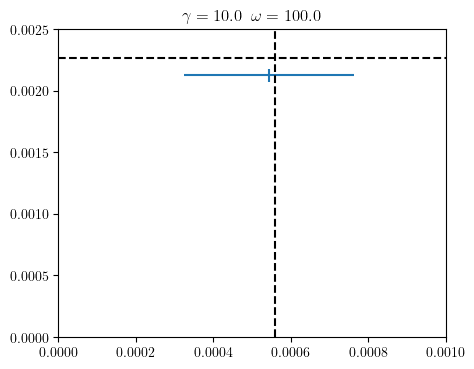

In [24]:
path = '/home/tohme/.julia/dev/LLROpt/data/'
data = json.load(open(path+dirname+fname))

logrates = data["1"][str(kg)][str(kw)][:-8]
irmix_mean = data["1"][str(kg)][str(kw)][-8]
irpure_mean = data["1"][str(kg)][str(kw)][-7]
irmix_stdev = data["1"][str(kg)][str(kw)][-6]
irpure_stdev = data["1"][str(kg)][str(kw)][-5]
g = data["1"][str(kg)][str(kw)][-2]
w = data["1"][str(kg)][str(kw)][-1]
cw = w*cr
x = cr / (cr+cw)

max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)
tau = (1/(1+w))*(1/(cr*dl_tf)+(1+w/g)/5)
max_ir_mix = 0.5 * (dc**2/(cr**2 + f(x,g)*(cr+cw)**2))/tau

plt.rcParams['text.usetex'] = True
fig, ax = plt.subplots(1,1,figsize=(5,4))

ax.errorbar(irmix_mean, irpure_mean, irpure_stdev, irmix_stdev)
ax.axhline(y=max_ir_full, linestyle="dashed", color="black")
ax.axvline(x=max_ir_mix, linestyle="dashed", color="black")
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)
ax.set_title(r"$\gamma={}\;\; \omega={}$".format(g, round(w, 1)))

if acc:
    edges = [(4,0), (0,4), (1,5), (5,1), (0,1), (0,2), (1,3),
             (1,0), (2,0), (2,3), (3,1), (3,2), (4,5), (5,4)]
    iedges = [(0,2), (1,3)]
    on_ind = np.array([0,1,0,1,0,1])
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
    logrates2 = [kuoff+np.log10(g), kboff+np.log10(cw), kbon+np.log10(cw), kuon+np.log10(g), 
        konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]
else:
    edges = [(0,1),(1,0),(0,2),(2,0)]
    iedges = [(0,1)]
    on_ind = np.array([0,1,1])
    kb, ku = logrates
    logrates2 = [kb, ku, kb+np.log10(cw), ku+np.log10(g)]


wedges = [(u,v,w) for ((u,v), w) in zip(edges, logrates2)]
wedges_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])
Q = utils.build_mat(wedges_lin, iedges, cr)
pss = ctmc.P_ss(Q)


G = nx.DiGraph()
for u, v, w in wedges_lin:
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)]) for i in G.nodes()]

if acc:

    node_labels = {0: r'FU',
                    1: r'NU',
                    2: r'FBR',
                    3: r'NBR',
                    4: r'FBW',
                    5: r'NBW'}

    node_numbers = {0: r'1',
                    1: r'2',
                    2: r'3',
                    3: r'4',
                    4: r'5',
                    5: r'6'}

    input_labels = {(0,4):"cw",
                    (0,2):"cr",
                    (1,5):"cw",
                    (1,3):"cr"}

else:
    node_labels = {0: r'U',
                    1: r'BC',
                    2: r'BW'}

    input_labels = {(0,1):"$ck_b$",
                    (0,2):"$\omega c k_b$",
                    (1,0):"$k_u$",
                    (2,0):"$\gamma k_u$"}

    # fig, ax, G = plot.draw_circuit(wedges_acc,
    #                             iedges, 
    #                             node_labels=node_labels, 
    #                             input_labels=input_labels,
    #                             bottom_set=[2,0,1],
    #                             node_size=1000,
    #                             node_color=node_color,
    #                             title="IR_acc",
    #                             dims=(5,2.8))

### Exploring optimal circuit statistics

In [485]:
k, kg, kw = (1,2,2)

In [427]:
pons = np.zeros(nbetas)
tbs = np.zeros(nbetas)
tons = np.zeros(nbetas)
toffs = np.zeros(nbetas)
sharps = np.zeros(nbetas)
vars = np.zeros(nbetas)
ir_mixs = np.zeros(nbetas)
lrspec = np.zeros(nbetas)
ir_pures = np.zeros(nbetas)
logrates_all = np.zeros((8, nbetas))
on_ind_pure = [0,1,0,1]
edges_pure = [(0,2),(0,1),(1,3),(1,0),(2,0),(2,3),(3,1),(3,2)]
g = gammas[kg-1]
w = wvals[kw-1]

for k, beta in enumerate(betas):
    logrates = data_acc[str(k+1)][str(kg)][str(kw)][:8]
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
    logrates2 = [kuoff+np.log10(g), kboff+np.log10(cw), kbon+np.log10(cw), kuon+np.log10(g), 
        konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]
    wedges_acc = np.array([(u,v,10**w) for ((u,v), w) in zip(edges_pure, logrates)])
    wedges_acc2 = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])
    Q = utils.build_mat(wedges_acc2, iedges, cr)
    pss = ctmc.P_ss(Q)
    pons[k] = ctmc.pi_on(wedges_acc2, iedges, cr, on_ind)
    lrspec[k] = np.log2((pss[3])/(pss[5]))
    ton, toff = ctmc.mean_fpt_part(wedges_acc2, iedges, cr, on_ind)
    tbs[k] = ton+toff
    tons[k] = ton
    toffs[k] = toff
    sharps[k] = ctmc.sharpness(wedges_acc2, iedges, cr, on_ind)
    ir_mixs[k] = ctmc.ir_acc(wedges_acc2, iedges, cr, dc, on_ind)
    ir_pures[k] = ctmc.ir_acc(wedges_acc, iedges, cr, dc, on_ind_pure)
    vars[k] = ctmc.var(wedges_acc2, iedges, cr, on_ind)
    logrates_all[:,k] = logrates

fig, ax = plt.subplots(1,1, figsize=(6,3.5))

# axr = ax.twinx()

# ax.plot(betas, ir_mixs)
# ax.plot(betas, ir_pures)
# ax.plot(betas, sharps)
# ax.plot(betas, lrspec)
# ax.plot(betas, tbs)
# ax.plot(betas, tons)
# ax.plot(betas, toffs)

ax.plot(betas, logrates_all[0,:], label="kboff")
ax.plot(betas, logrates_all[1,:], label="konu")
ax.plot(betas, logrates_all[2,:], label="kbon")   #
ax.plot(betas, logrates_all[3,:], label="koffu")  #
ax.plot(betas, logrates_all[4,:], label="kuoff")  #
ax.plot(betas, logrates_all[5,:], label="konb")
ax.plot(betas, logrates_all[6,:], label="kuon")
ax.plot(betas, logrates_all[7,:], label="koffb")  #

# axr.plot(betas, pons, color='C3')
# axr.plot(betas, vars, color='C4')
ax.axhline(y=np.log2(g/w), linestyle='dashed')

ax.set_xscale('log')
# axr.set_ylabel(r"$p_{ON}$", fontsize=16)
# ax.set_ylabel(r"$\tau_{B}$", fontsize=16)
ax.set_xlabel(r"$\beta$", fontsize=16)
ax.legend(loc='lower center', fontsize=8)

NameError: name 'nbetas' is not defined

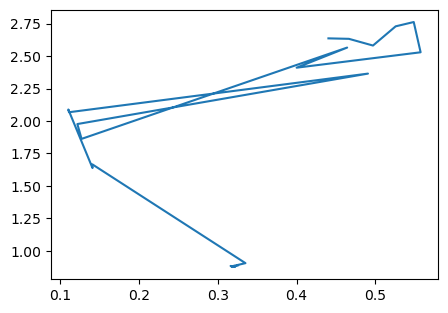

In [635]:
fig, ax = plt.subplots(1,1, figsize=(5,3.5))

ax.plot(pons, tbs)

# Multiple binding sites

## 2 binding sites

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


(<Figure size 500x280 with 2 Axes>,
 <Axes: >,
 <networkx.classes.digraph.DiGraph at 0x70d49ad91410>)

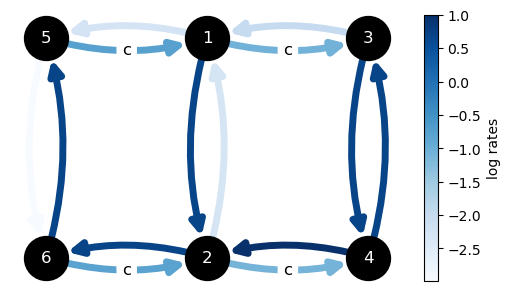

In [782]:
edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                  (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1    

kboff = -1.0613204
konu = -2.98726
kbon = -1.0868188
koffu = 0.7
kuoff = -2.276372
kon1b = 0.7
kuon = 0.7
koff1b = -2.2888334 
kon2b = 0.7
koff2b = 0.7
logrates = [kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b]

# logrates = [-1.0515876,
#               -3,
#               -1.0515876,
#               0.69896996,
#               -2.9974964,
#               0.69896996,
#               0.6989698,
#               -2.9998689,
#               0.69896996,
#               -2.9999237]

kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]

wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
iedges = [(0,2), (1,3), (4,0), (5,1)]
on_ind = np.concatenate((np.zeros(3), np.ones(3)))
node_labels = dict(zip(range(6), range(1,7)))
# node_color = [0] * 6
# node_color[0] = 1
input_labels = dict(zip(iedges, ['c']*4))
bottom_set = [5,1,3]
node_size=1000

G = nx.DiGraph()
for u, v, w in wedges:
    # print("edge: ({},{})".format(u, v), "weight: {}".format(w))
    G.add_edge(u, v, weight=w)

# if node_color != "black":
#     node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]

plot.draw_circuit(wedges, 
                  iedges, 
                  node_labels=node_labels, 
                  input_labels=input_labels,
                  bottom_set=bottom_set,
                  node_size=node_size,
                  node_color="black",
                #   title="2 binding sites",
                  dims=(5,2.8))

In [346]:
import matplotlib.pyplot as plt

def plot_ir_ep(figax, color="black", label="", ncpus=16, nparams_per_cpu=1, k_=1):
    a = 3e-3        # um
    D_tf = 7.4      # um^2/s
    cr = 5.6         # um^-3
    dc = 0.1 * cr
    dl_tf = 4*a*D_tf
    ub = 5
    max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)

    irkey = nedges
    data_full = {}
    data_acc = {}
    data_acc_proc = {}
    betakeys = np.arange(1, ncpus+1)

    for cpukey in range(1, ncpus+1):
        if cpukey not in skipkeys:
            # data_full_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_vs_ep_pareto_4s_beta{}.json'.format(dirname, cpukey)))
            # data_acc_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_acc_vs_ep_pareto_4s_beta{}.json'.format(dirname, cpukey)))
            data_full_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

            for k in range(1, nparams_per_cpu+1):
                betakey = (cpukey - 1)*nparams_per_cpu + k
                if betakey not in skipkeys:
                    data_full[betakey] = data_full_proc[str(betakey)]

    irvals_full = [data_full[i][irkey] for i in betakeys if i not in skipkeys]
    epvals_full = [data_full[i][irkey+1] for i in betakeys if i not in skipkeys]

    if whichf == "full":
        irvals_full_std = [data_full[i][irkey+2] for i in betakeys if i not in skipkeys]

    plt.rcParams['text.usetex'] = True

    if figax == None:
        fig, ax = plt.subplots(1,1, layout='constrained', figsize=(4.5,3))
    else:
        fig, ax = figax

    ax.axhline(y=irvals_full[k_], color="gray", linewidth=0.5)
    ax.axvline(x=epvals_full[k_], color="gray", linewidth=0.5)

    ax.errorbar(epvals_full, irvals_full,  marker='o', linestyle='none', capsize=2, color=color, label=label)
    ax.set_ylabel(r"$\langle T \rangle^*$", fontsize=18)
    ax.set_xlabel(r"$EP^*$", fontsize=18)
    ax.set_title("Decision error = 0.37")

    logrates = data_full[k_][:irkey]
    kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

    weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                 koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]

    edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                      (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1

    wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
    wedges_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights)])
    iedges = [(0,2), (1,3), (4,0), (5,1)]
    on_ind = np.concatenate((np.zeros(3), np.ones(3)))
    node_labels = dict(zip(range(6), range(1,7)))
    # node_color = [0] * 6
    # node_color[0] = 1
    input_labels = dict(zip(iedges, ['c']*4))
    bottom_set = [5,1,3]
    node_size=1000

    Q = utils.build_mat(wedges_lin, iedges, cr)
    pss = ctmc.P_ss(Q)

    G = nx.DiGraph()
    for u, v, w in wedges:
        G.add_edge(u, v, weight=w)

    # node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]
    node_color = np.zeros(6)
    node_color[0] = 1

    plot.draw_circuit(wedges, 
                    iedges, 
                    node_labels=node_labels, 
                    input_labels=input_labels,
                    bottom_set=bottom_set,
                    node_size=node_size,
                    node_color=node_color,
                    #   title="2 binding sites",
                    dims=(5,2.8))

    return fig, ax, data_full #, figcirc

In [572]:
def plot_data(figax=None, color="black", figsize=None):
    paramfile = "params"
    path = '/home/tohme/.julia/dev/LLROpt/data/'
    params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

    data_acc = {}
    data_acc_proc = {}
    ncpus = params_acc["ncpus"]
    nbetas = params_acc["nparams"]
    betas = params_acc["betas"]
    nparams_per_cpu = int(nbetas/ncpus)

    for cpukey in range(1, ncpus + 1):
        data_acc_proc = json.load(open(path+'{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

        for i in range(1, nparams_per_cpu+1):
            keyb = (cpukey - 1) * nparams_per_cpu + i
            data_acc[keyb] = data_acc_proc[str(keyb)]

    irvals = [data_acc[i][nedges] for i in range(1, nbetas+1)]
    epvals = [data_acc[i][nedges+1] for i in range(1, nbetas+1)]

    if figax is None:
        figplot, ax = plt.subplots(1,1, layout='constrained', figsize=figsize)
    else:
        figplot, ax = figax

    ax.errorbar(epvals, irvals,  marker='o', linestyle='none', capsize=2, color=color, markersize=msize)

    if showlines:
        ax.axhline(y=irvals[k-1], color="gray", linewidth=0.5)
        ax.axvline(x=epvals[k-1], color="gray", linewidth=0.5)

    return figplot, ax, data_acc

def plot_circuit_2bs(k=1, node_color=None, input_labels=None):
    paramfile = "params"
    path = '/home/tohme/.julia/dev/LLROpt/data/'
    params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

    data_acc = {}
    data_acc_proc = {}
    ncpus = params_acc["ncpus"]
    nbetas = params_acc["nparams"]
    betas = params_acc["betas"]
    nparams_per_cpu = int(nbetas/ncpus)

    for cpukey in range(1, ncpus + 1):
        data_acc_proc = json.load(open(path+'{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

        for i in range(1, nparams_per_cpu+1):
            keyb = (cpukey - 1) * nparams_per_cpu + i
            data_acc[keyb] = data_acc_proc[str(keyb)]

    logrates = data_acc[k][:nedges]
    kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

    weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                 koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]

    edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                      (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1

    wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
    wedges_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights)])
    iedges = [(0,2), (1,3), (4,0), (5,1)]
    on_ind = np.concatenate((np.zeros(3), np.ones(3)))
    # node_labels = dict(zip(range(6), range(1,7)))
    # node_color = [0] * 6
    # node_color[0] = 1
    if input_labels is None:
        input_labels = dict(zip(iedges, ['c']*4))
    bottom_set = [5,1,3]
    node_size=1000

    Q = utils.build_mat(wedges_lin, iedges, cr)
    pss = ctmc.P_ss(Q)

    # node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]
    # node_color = np.zeros(6)

    _, _, H = plot.draw_circuit(wedges, 
                    iedges, 
                    node_labels=node_labels, 
                    input_labels=input_labels,
                    bottom_set=bottom_set,
                    node_size=node_size,
                    node_color=node_color,
                    dims=(5,2.8))

    return H

In [944]:
k = 59
which = "full"

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


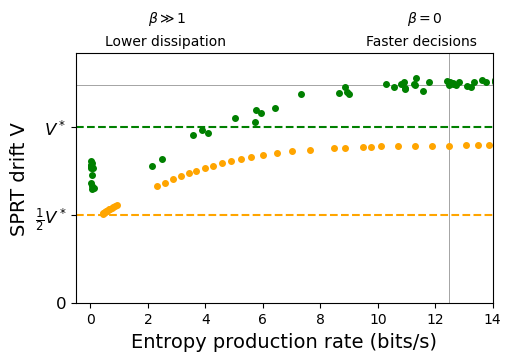

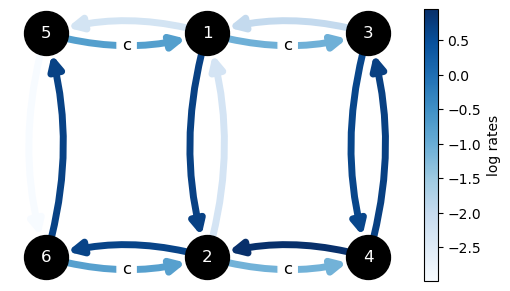

In [945]:
# dirname = '20241130/2bs-ir-ep/test'
dirname = '20241203/2bs-ir-ep/test-forcing-konu-de'
# dirname = '20241202/2bs-ir-ep/test-forcing-5-6-de'

plt.rcParams["text.usetex"] = False
nedges = 10
showlines = True if which == "acc" else False
# showlines = False
whichf = "acc"
msize=4
fig, ax, data_acc = plot_data(None, "orange", (5,3.5))
ax.set_title("")
ax.axhline(y=D_full2b, linestyle="dashed", color="green")
ax.axhline(y=D_full2b/2, linestyle="dashed", color="orange")
ax.set_ylabel("SPRT drift V", fontsize=14)
ax.set_xlabel("Entropy production rate (bits/s)", fontsize=14)
ax.set_ylim(0,32e-4)
ax.set_xlim(-0.5, 14)
ax.set_yticks([0,D_full2b/2,D_full2b])
ax.set_yticklabels([0, r"$\frac{1}{2}V^*$", r"$V^*$"], fontsize=12)
# ax.set_xscale('log')

ax.text(0.5,3.3e-3,"Lower dissipation", fontsize=10)
ax.text(2,3.6e-3,r"$\beta \gg 1$", fontsize=10)
ax.text(9.6,3.3e-3,"Faster decisions", fontsize=10)
ax.text(11,3.6e-3,r"$\beta = 0$", fontsize=10)
x = np.linspace(-0.5, 14, 100)
y = np.linspace(0, 1, 100)
X, Y = np.meshgrid(x, y)
Z = X + Y  # This will create a simple gradient effect
# ax.imshow(Z, extent=[-0.5, 14, 0, 1], origin='lower', aspect='auto', cmap='coolwarm', alpha=0.2)

dirname = '20241203/2bs-ir-ep/'
whichf = "full"
showlines = True if which == "full" else False
# showlines = False
fig, ax, data_full = plot_data((fig,ax), "green")

logrates = data_acc[k][:10] if which == "acc" else data_full[k][:10]
kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates
e = (0,1)
input_labels = None
# input_labels= {e:'pimp'}
cr = 5.6
# dirname = '20241203/2bs-ir-ep/test-forcing-konu-de'
dirname = '20241203/2bs-ir-ep/' if which == "full" else '20241203/2bs-ir-ep/test-forcing-konu-de'
whichf = which
G = plot_circuit_2bs(k, node_color="black", input_labels=input_labels)

In [ ]:
date = 20241210
dirname = '/home/tohme/phd/flython/plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('/home/tohme/phd/flython/plots/{}/ir-ep-with-opt-circuits.pdf'.format(date))

In [990]:
X = np.array([data_full[i][:10] for i in range(1,61)])

X4_embedded = TSNE(n_components=2, learning_rate='auto',
                    init='random', perplexity=5).fit_transform(X)

hdb4d = HDBSCAN()
hdb4d.fit(X4_embedded)

HDBSCAN()

label: 0


/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


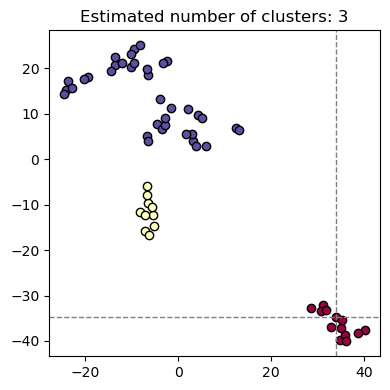

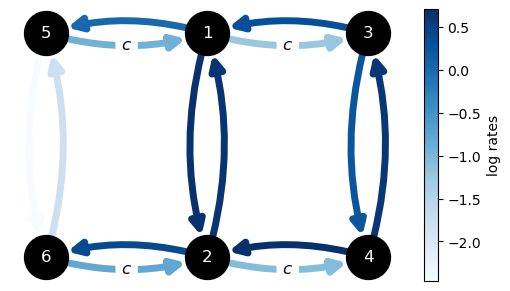

In [1030]:
key = 12
print("label:", hdb4d.labels_[key])

ax = plot_clusters(X4_embedded, hdb4d.labels_)
ax.axvline(x=X4_embedded[key][0], linestyle="dashed", color="gray", lw=1)
ax.axhline(y=X4_embedded[key][1], linestyle="dashed", color="gray", lw=1)

kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = X[key]
weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
_ = plot.draw_circuit(wedges, 
                  iedges, 
                  node_labels=node_labels, 
                  input_labels=input_labels,
                  bottom_set=bottom_set,
                  node_size=node_size,
                  node_color="black",
                  dims=(5,2.8))

In [1019]:
hdb4d.labels_

array([0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

## 6 binding sites

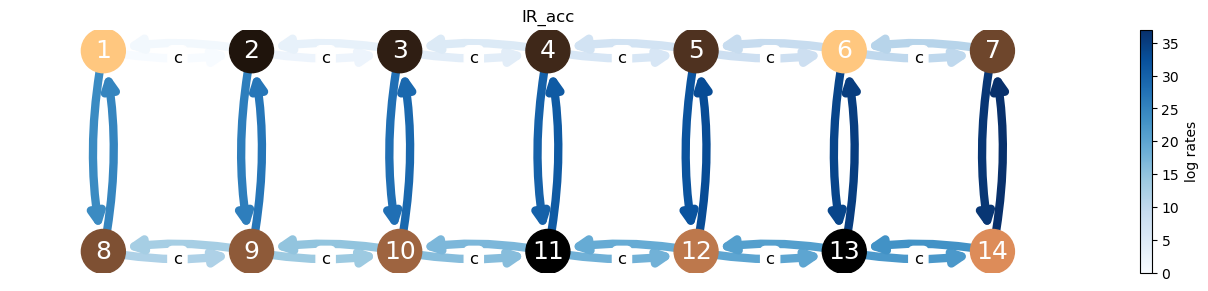

(<Figure size 1200x280 with 2 Axes>,
 <Axes: title={'center': 'IR_acc'}>,
 <networkx.classes.digraph.DiGraph at 0x7c9d28a15850>)

In [316]:
import networkx as nx
importlib.reload(plot)

edges = [(1 ,2 ), (2 ,1 ),
         (2 ,3 ), (3 ,2 ),
         (3 ,4 ), (4 ,3 ),
         (4 ,5 ), (5 ,4 ),
         (5 ,6 ), (6 ,5 ),
         (6 ,7 ), (7 ,6 ),
         (8 ,9 ), (9 ,8 ),
         (9 ,10), (10,9 ),
         (10,11), (11,10),
         (11,12), (12,11),
         (12,13), (13,12),
         (13,14), (14,13),
         (1 ,8 ), (8 ,1 ),
         (2 ,9 ), (9 ,2 ),
         (3 ,10), (10,3 ),
         (4 ,11), (11,4 ),
         (5 ,12), (12,5 ),
         (6 ,13), (13,6 ),
         (7 ,14), (14,7 )]

weights = np.arange(len(edges))
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
iedges = [(i,i+1) for i in range(1,14) if i != 7]
on_ind = np.concatenate((np.zeros(7), np.ones(7)))
node_labels = dict(zip(range(1,15), range(1,15)))
node_color = [20,2,3,4,5,20,7,8,9,10,0,12,0,14]
input_labels = dict(zip(iedges, ['c']*14))
bottom_set = range(8,15)
node_size=1000

plot.draw_circuit(wedges, 
                  iedges, 
                  node_labels=node_labels, 
                  input_labels=input_labels,
                  bottom_set=bottom_set,
                  node_size=node_size,
                  node_color=node_color,
                  title="IR_acc",
                  dims=(12,2.8))

In [317]:
kb = 3
dirname1 = '20241002/6bs'
node_color=""
which_ir = "acc"

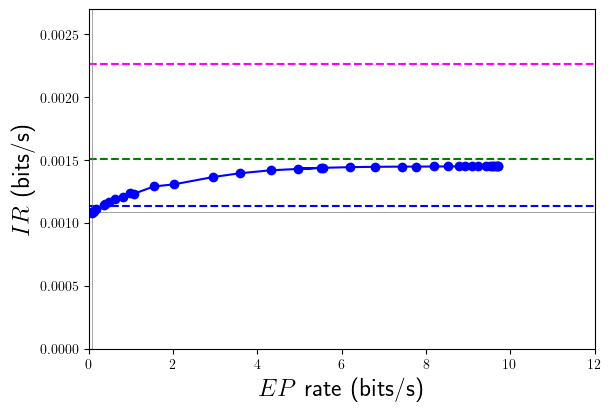

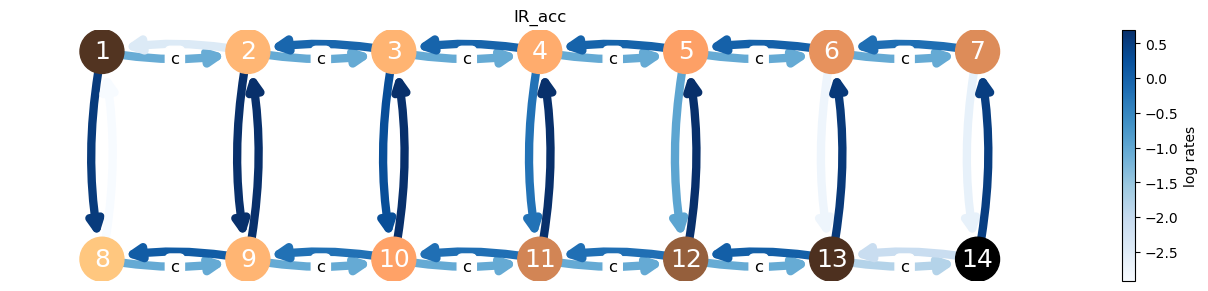

In [319]:
import matplotlib.pyplot as plt
importlib.reload(plot)

########## 6 bs

params_acc1 = json.load(open(path+'{}/params.json'.format(dirname1)))
data_acc = {}
data_acc_proc1 = {}
ncpus = params_acc1["ncpus"]
nparams = params_acc1["nparams"]
betakeys = np.arange(1, nparams+1)
nparams_per_cpu = int(nparams/ncpus)

for cpukey in range(1, ncpus+1):
    data_acc_proc1 = json.load(open(path+'{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname1, which_ir, cpukey)))

    for k in range(1, nparams_per_cpu+1):
        betakey = (cpukey - 1)*nparams_per_cpu + k
        data_acc[betakey] = data_acc_proc1[str(betakey)]

nvals = len(data_acc.keys())
irvals_acc1 = [data_acc[i][-2] for i in betakeys]
# irstdev_acc1 = [data_acc[i][-1] for i in betakeys]
epvals_acc1 = [data_acc[i][-1] for i in betakeys]

plt.rcParams['text.usetex'] = True

fig1, ax = plt.subplots(1,1, layout='constrained', figsize=(6,4))

ax.errorbar(epvals_acc1, irvals_acc1, linestyle='solid',marker='o', color='blue')
# ax.plot(epvals_acc2, irvals_acc2, marker='o', color='green')
ax.axhline(y=0.0022614, color='magenta', linestyle='dashed')
ax.axhline(y=0.0022614/2, color='blue', linestyle='dashed')
ax.axhline(y=0.0022614*2/3, color='green', linestyle='dashed')
ax.axhline(y = data_acc[kb][-2], linewidth=0.5, color="gray")
ax.axvline(x = data_acc[kb][-1], linewidth=0.5, color="gray")
ax.set_ylim(0,0.0027)
ax.set_xlim(0, 12)
ax.set_ylabel(r"$IR$ (bits/s)", fontsize=18)
ax.set_xlabel(r"$EP$ rate (bits/s)", fontsize=18)

weights = np.array(data_acc[kb][:len(edges)])
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])

wedges_lin = np.array([(u-1,v-1,10**w) for ((u,v),w) in zip(edges, weights)])
iedges_py = [(u-1,v-1) for (u,v) in iedges]
Q = utils.build_mat(wedges_lin, iedges_py, cr)
pss = ctmc.P_ss(Q)

G = nx.DiGraph()
for u, v, w in wedges:
    # print("edge: ({},{})".format(u, v), "weight: {}".format(w))
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]

fig2, ax, _ = plot.draw_circuit(
    wedges, 
    iedges,
    node_labels=node_labels, 
    input_labels=input_labels,
    bottom_set=bottom_set,
    node_size=node_size,
    node_color=node_color,
    title="IR_acc",
    dims=(12,2.8)
)

In [497]:
fig1.savefig('plots/6bs_irfull_ir_vs_ep_not_converging_20241005.pdf')
fig2.savefig('plots/6bs_circuit_not_converged.pdf')

# Better estimator for V

### Testing estimators with a real Gaussian process

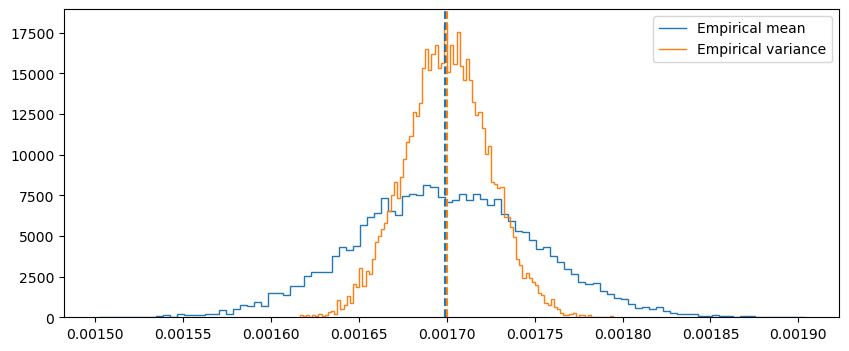

In [107]:
date = 20240822
data1 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/empirical_mean_estimator.json'.format(date)))
data2 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/empirical_variance_estimator.json'.format(date)))
# data3 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/20240809/maximum_likelihood_estimator.json'))

fig, ax = plt.subplots(1,1, figsize=(10,4))

h1, edges1 = np.histogram(data1, bins=100, density=True)
h2, edges2 = np.histogram(data2, bins=100, density=True)
# h3, edges3 = np.histogram(data3, bins=30, density=True)

ax.stairs(h1, edges1, label='Empirical mean')
ax.stairs(h2, edges2, label='Empirical variance')
# ax.stairs(h3, edges3, label='MLE given V=D')

ax.axvline(x=np.mean(data1), linestyle='dashed', color='C0')
ax.axvline(x=np.mean(data2), linestyle='dashed', color='C1')
# ax.axvline(x=np.mean(data3), linestyle='dashed', color='C2')
# ax.set_xlim(80, 120)

ax.legend()

In [151]:
fig.savefig('plots/estimators_comparison_20240809.pdf')

### How gaussian are LLR increments?

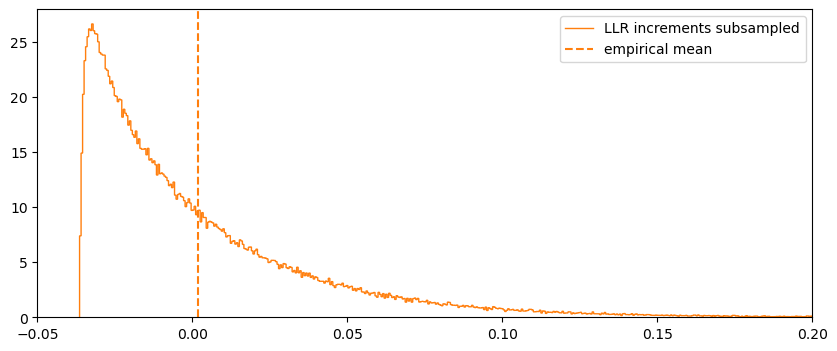

In [5]:
date = 20240822
# data1 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/llr_incrs.json'.format(date)))
data2 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/llr_incrs_sub.json'.format(date)))

c = 5.6
kb = 0.0888
kon = 5
ku = 5
koff = 5
n = 10000000
k = 5000000
dt = (1/(c*kb) + 1/kon + 1/ku + 1/koff) * (n/k) / 2
V = 0.0017
sigma = np.sqrt(2*V*dt)
xvals = np.linspace(V*dt-4*sigma, V*dt+4*sigma, 1000)

fig, ax = plt.subplots(1,1, figsize=(10,4))

# h1, edges1 = np.histogram(data1, bins=100, density=True)
h2, edges2 = np.histogram(np.array(data2)/dt, bins=1000, density=True)

# ax.stairs(h1, edges1, label='LLR increments', color='C0')
ax.stairs(h2, edges2, label='LLR increments subsampled', color='C1')

# ax.axvline(x=np.mean(data1), linestyle='dashed', color='C0')
ax.axvline(x=np.mean(data2)/dt, linestyle='dashed', color='C1', label="empirical mean")

norm = np.exp(-(xvals - V*dt)**2/(2*sigma**2)) / np.sqrt(2*np.pi*sigma**2)
# ax.plot(xvals/dt, norm, color='C2')
# ax.axvline(x=V*dt, linestyle='dashed', color='C2', label="true mean")
ax.set_xlim(-0.05, 0.2)
ax.legend()

In [18]:
print("empirical D:", np.var(data2)/(2*dt))
print("empirical V:", np.mean(data2)/dt)

empirical D: 0.0018980577150951967
empirical V: 0.0017631688717462905


### Testing mean and var estimators with our LLR process

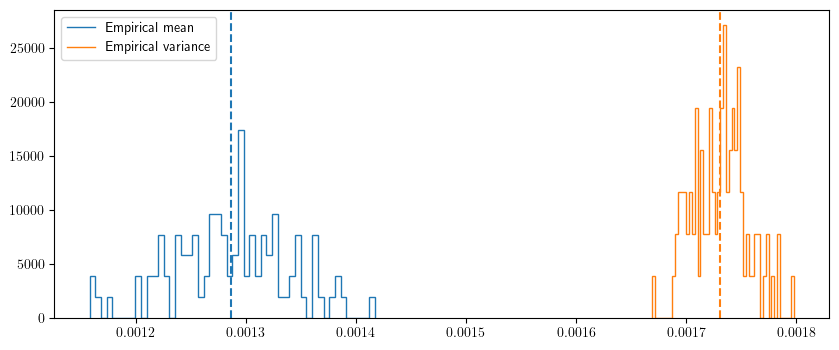

In [91]:
# date = 20241103
# date = 20241111
date = 20241125
data1 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_mean_estimator.json'.format(date)))
# data2 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_variance_estimator.json'.format(date)))

fig, ax = plt.subplots(1,1, figsize=(10,4))

h1, edges1 = np.histogram(data1, bins=50, density=True)
# h2, edges2 = np.histogram(data2, bins=50, density=True)

ax.stairs(h1, edges1, label='Empirical mean')
# ax.stairs(h2, edges2, label='Empirical variance')

ax.axvline(x=np.mean(data1), linestyle='dashed', color='C0')
# ax.axvline(x=np.mean(data2), linestyle='dashed', color='C1')

ax.legend()

In [184]:
dirname = 'plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig(dirname+'/ir_full_mean_and_variance_estimators_subsamp_5.pdf')

### Testing V=D and decision-time distribution

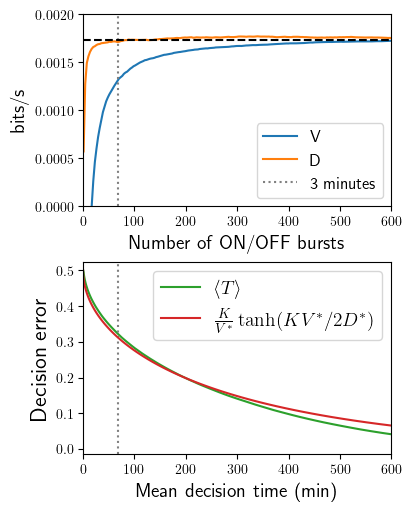

In [294]:
dirname = "20241103/"
# dirname = "20241102/max_iracc_circuit/" 
# dirname = "20241102/max_IR_equilibrium_circuit/"
path = '/home/tohme/.julia/dev/LLROpt/data/'
data1 = json.load(open(path+'{}ir_full_samples.json'.format(dirname)))
data2 = json.load(open(path+'{}stop_times_llr.json'.format(dirname)))
data3 = json.load(open(path+'{}stop_times_gp.json'.format(dirname)))

n = 5000
ntimes = len(data1)
nruns = len(data1[0])
nerrs = len(data2)

c = 5.6
kb = 0.0888
kon = 5
ku = 5
koff = 5
taub = (1/(c*kb) + 1/kon + 1/ku + 1/koff)
times = np.linspace(taub, n*taub/8, ntimes)
errs = np.linspace(0.5, 1e-2, nerrs)

V = np.mean(np.array(data1), axis=1)
D = np.var(np.array(data1) * np.sqrt(times)[:,None], axis=1) / 2

plt.rcParams['text.usetex'] = True
fig, ax = plt.subplots(2,1, figsize=(4,5), layout="constrained")

ax[0].plot(times/taub, V, label="V")
ax[0].plot(times/taub, D, label="D")
ax[0].set_ylim(0, 0.002)
ax[0].set_xlim(0, 600)
ax[0].axvline(x=180/taub, linestyle="dotted", color="gray", label="3 minutes")
ax[0].axhline(y=0.001728, linestyle="dashed", color="black")
ax[0].set_xlabel("Number of ON/OFF bursts", fontsize=14)
ax[0].set_ylabel(r"bits/s", fontsize=14)
ax[0].legend(fontsize=12)

mean_stoptimes = np.mean(np.array(data2), axis=1)
Ks = np.log((1-errs)/errs)

ax[1].plot(mean_stoptimes/taub, errs, label=r"$\langle T \rangle$", color="C2")
ax[1].set_xlabel("Mean decision time (min)", fontsize=14)
ax[1].set_ylabel("Decision error", fontsize=16)
ax[1].set_xlim(0, 600)
ax[1].axvline(x=180/taub, linestyle="dotted", color="gray")
key = 21
ax[1].plot(Ks * np.tanh(Ks*V[key]/(2*D[key]))/(V[key]*taub), 
           errs, label="$\\frac{K}{V^*}\\tanh(KV^*/2D^*)$", color="C3")
ax[1].legend(fontsize=14)

In [19]:
import os

path = 'plots/'+dirname
if not os.path.exists(path):
    os.makedirs(path)

fig.savefig('plots/{}V_and_D_pre_asymptotics.pdf'.format(dirname))

(0.0, 40.0)

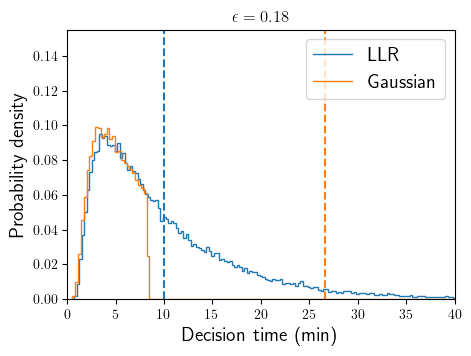

In [306]:
fig, ax = plt.subplots(1,1, figsize=(5,3.5))

ierrs = [65]
# ax.set_title("Decision time density")
ax.set_xlabel("Decision time (min)", fontsize=14)
ax.set_ylabel("Probability density", fontsize=14)

for (i, ierr) in enumerate(ierrs):
    ax.set_title(r"$\epsilon = {}$".format(round(errs[ierr],2)))
    h1, edges1 = np.histogram(np.array(data2[ierr])/60, bins=200, density=True)
    h2, edges2 = np.histogram(np.array(data3[ierr])/60, bins=200, density=True)

    ax.stairs(h1, edges1, label="LLR")
    ax.stairs(h2, edges2, label="Gaussian")

    ax.axvline(x=np.mean(data2[ierr])/60, linestyle='dashed', color="C{}".format(i))
    ax.axvline(x=np.mean(data3[ierr])/60, linestyle='dashed', color="C{}".format(i+1))

r,l = ax.get_xlim()
ax.set_xlim(r/3, l/4)
ax.legend(fontsize=14)
ax.set_xlim(0, 40)

In [116]:
print("<T>_LLR / <T>_GP - 1 ~", (np.mean(data2[ierr])/np.mean(data3[ierr]) - 1) * 100, "%")

<T>_LLR / <T>_GP - 1 ~ 11.927870349568614 %


Text(0, 0.5, 'ET')

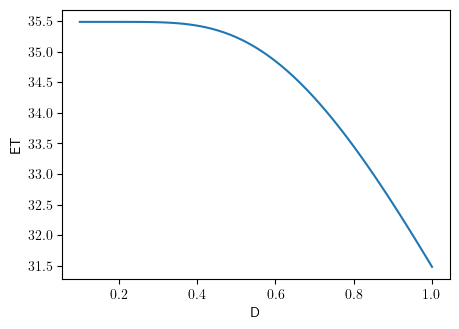

In [155]:
# fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

K = 10
vs = np.linspace(0.1, 1, 100)
ds = np.linspace(0.1, 1, 100)
x, y = np.meshgrid(vs, ds)
z = (K / x) * np.tanh(K*x/(2*y))
# ax.plot_surface(x, y, z)
# ax.set_xlabel("V")
# ax.set_ylabel("D")

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

vx = vs[20]
c = 1
# vx = ds * c
ax.plot(ds, (K / vx) * np.tanh(K*vx/(2*ds)))
ax.set_xlabel("D")
ax.set_ylabel("ET")

### Improving decision-time statistics

In [ ]:
# extract multiple decision events from a single fixed-time trajectory

### RMC estimator (importance sampling)

state of affairs as of 20240927:
- RMC code is wrong (doesn't agree with old code's estimate)
- about 8x slower
- uses 3x as much memory

wrong: 
it's not calculating the same thing. i'm using RS as matrices, assuming the traj starts in the same partition, there's plenty of room for bugs.

slow:
seems to be a problem with get_residence_time and generate. the ll code seems to be fast.

memory:
fine-tuning.

Léo Regnier: use a score that adds more weight to the trajectories that contribute the most variance to your estimator. This may be different than RMC if you're only interested in the first moment. you need to make sure your resampling obeys detailed balance - ergodicity

# IR limits

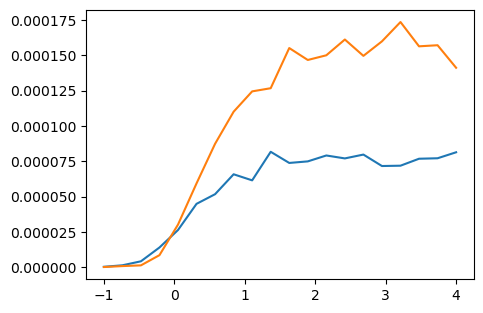

In [802]:
path = '/home/tohme/.julia/dev/LLROpt/data/20241211/irlimit/'
data_1bs = json.load(open(path+'ir_full_1bs_scaling.json'))
data_2bs = json.load(open(path+'ir_full_2bs_scaling.json'))

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

kvals = [data_1bs[str(i)]["k"] for i in range(1, 21)]
vals_1bs = [data_1bs[str(i)]["val"] for i in range(1, 21)]
vals_2bs = [data_2bs[str(i)]["val"] for i in range(1, 21)]
ax.plot(kvals, vals_1bs)
ax.plot(kvals, vals_2bs)

In [799]:
data_1bs

{'5': {'k': 0.05263158, 'val': 4.2526455e-05},
 '16': {'k': 2.9473684, 'val': 9.912928e-05},
 '20': {'k': 4.0, 'val': 9.279351e-05},
 '12': {'k': 1.8947369, 'val': 6.7211586e-05},
 '8': {'k': 0.84210527, 'val': 0.00011297549},
 '17': {'k': 3.2105262, 'val': 0.00017269621},
 '1': {'k': -1.0, 'val': 2.6991715e-06},
 '19': {'k': 3.7368422, 'val': 2.6776963e-06},
 '6': {'k': 0.31578946, 'val': 1.7568022e-05},
 '11': {'k': 1.6315789, 'val': 0.00012858593},
 '9': {'k': 1.1052631, 'val': 0.000109680135},
 '14': {'k': 2.4210527, 'val': 7.83797e-05},
 '3': {'k': -0.47368422, 'val': 2.1924034e-06},
 '7': {'k': 0.57894737, 'val': 3.084719e-05},
 '4': {'k': -0.21052632, 'val': 1.3321236e-05},
 '13': {'k': 2.1578948, 'val': 7.316187e-05},
 '15': {'k': 2.6842105, 'val': 0.000101864716},
 '2': {'k': -0.7368421, 'val': 4.4500334e-06},
 '10': {'k': 1.3684211, 'val': -1.05172185e-05},
 '18': {'k': 3.4736843, 'val': 6.3960586e-05}}

# Inferring circuits from traces